# Problem Statement

## **Business Context**

"Visit with Us," a leading travel company, is revolutionizing the tourism industry by leveraging data-driven strategies to optimize operations and customer engagement. While introducing a new package offering, such as the Wellness Tourism Package, the company faces challenges in targeting the right customers efficiently. The manual approach to identifying potential customers is inconsistent, time-consuming, and prone to errors, leading to missed opportunities and suboptimal campaign performance.

To address these issues, the company aims to implement a scalable and automated system that integrates customer data, predicts potential buyers, and enhances decision-making for marketing strategies. By utilizing an MLOps pipeline, the company seeks to achieve seamless integration of data preprocessing, model development, deployment, and CI/CD practices for continuous improvement. This system will ensure efficient targeting of customers, timely updates to the predictive model, and adaptation to evolving customer behaviors, ultimately driving growth and customer satisfaction.


## **Objective**

As an MLOps Engineer at "Visit with Us," your responsibility is to design and deploy an MLOps pipeline on GitHub to automate the end-to-end workflow for predicting customer purchases. The primary objective is to build a model that predicts whether a customer will purchase the newly introduced Wellness Tourism Package before contacting them. The pipeline will include data cleaning, preprocessing, transformation, model building, training, evaluation, and deployment, ensuring consistent performance and scalability. By leveraging GitHub Actions for CI/CD integration, the system will enable automated updates, streamline model deployment, and improve operational efficiency. This robust predictive solution will empower policymakers to make data-driven decisions, enhance marketing strategies, and effectively target potential customers, thereby driving customer acquisition and business growth.

## **Data Description**

The dataset contains customer and interaction data that serve as key attributes for predicting the likelihood of purchasing the Wellness Tourism Package. The detailed attributes are:

**Customer Details**
- **CustomerID:** Unique identifier for each customer.
- **ProdTaken:** Target variable indicating whether the customer has purchased a package (0: No, 1: Yes).
- **Age:** Age of the customer.
- **TypeofContact:** The method by which the customer was contacted (Company Invited or Self Inquiry).
- **CityTier:** The city category based on development, population, and living standards (Tier 1 > Tier 2 > Tier 3).
- **Occupation:** Customer's occupation (e.g., Salaried, Freelancer).
- **Gender:** Gender of the customer (Male, Female).
- **NumberOfPersonVisiting:** Total number of people accompanying the customer on the trip.
- **PreferredPropertyStar:** Preferred hotel rating by the customer.
- **MaritalStatus:** Marital status of the customer (Single, Married, Divorced).
- **NumberOfTrips:** Average number of trips the customer takes annually.
- **Passport:** Whether the customer holds a valid passport (0: No, 1: Yes).
- **OwnCar:** Whether the customer owns a car (0: No, 1: Yes).
- **NumberOfChildrenVisiting:** Number of children below age 5 accompanying the customer.
- **Designation:** Customer's designation in their current organization.
- **MonthlyIncome:** Gross monthly income of the customer.

**Customer Interaction Data**
- **PitchSatisfactionScore:** Score indicating the customer's satisfaction with the sales pitch.
- **ProductPitched:** The type of product pitched to the customer.
- **NumberOfFollowups:** Total number of follow-ups by the salesperson after the sales pitch.-
- **DurationOfPitch:** Duration of the sales pitch delivered to the customer.


## My Approach (Summary)
I set this project up the way it would run in production rather than as a one-off notebook:
1. **Data Registration** – the raw CSV lives inside the repo (`tourism_project/data/tourism.csv`) and a validation script checks the schema before anything else runs.
2. **Data Preparation** – a script cleans the data (index column, `CustomerID`, the `Fe Male` typo, `Unmarried`/`Single`, duplicates) and creates a stratified train/test split.
3. **Model Building** – an XGBoost pipeline (scaling + one-hot encoding + classifier) tuned with `GridSearchCV`; every parameter combination and the final metrics are logged to **MLflow**.
4. **Deployment** – a Streamlit app that loads the model the pipeline commits back to the repo.
5. **CI/CD** – a GitHub Actions workflow (`pipeline.yml`) that chains all of the above as separate jobs, passes data between them as artifacts, and pushes the trained model back to `main`.

Before writing the pipeline scripts I explored the data in this notebook so the cleaning and modelling choices are backed by what I actually saw.

## Pre-requisites
This project uses **GitHub Actions** for the ML pipeline and **Streamlit Community Cloud** for the live app.
- A GitHub Personal Access Token (classic) with `repo` and `workflow` scopes, stored as a Colab secret named `GH_TOKEN`.
- A Streamlit Community Cloud account (https://share.streamlit.io) signed in with the same GitHub account.
- MLflow is used for experiment tracking. Locally I log to a file-based store (`./mlruns`); inside GitHub Actions the workflow starts an MLflow server on port 5000 and the training script logs to it.

## Installing and Importing Necessary Libraries

In [1]:
# Installing the libraries with the versions used throughout this project
# (the same versions are pinned in requirements.txt so GitHub Actions and Streamlit Cloud match)
!pip install -q PyGithub==2.9.1 mlflow==3.1.0 xgboost==2.1.4 scikit-learn==1.6.1 pandas==2.2.3 seaborn

**Note:** After running the above cell in Colab, restart the runtime once and run all cells sequentially from the next cell.

In [2]:
import os
import warnings
warnings.filterwarnings("ignore")

# GitHub API client (used only in the push step)
from github import Github, GithubException

# Data handling and visualisation
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Modelling
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import make_column_transformer
from sklearn.pipeline import make_pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (BaggingClassifier, RandomForestClassifier,
                              AdaBoostClassifier, GradientBoostingClassifier)
from sklearn.metrics import (classification_report, confusion_matrix, accuracy_score,
                             precision_score, recall_score, f1_score, roc_auc_score)
import xgboost as xgb
import joblib
import mlflow

pd.set_option("display.max_columns", 30)
sns.set_style("whitegrid")
print("Libraries loaded | pandas", pd.__version__, "| xgboost", xgb.__version__, "| mlflow", mlflow.__version__)

Libraries loaded | pandas 2.2.3 | xgboost 2.1.4 | mlflow 3.1.0


## Configuration

In [3]:
# Repository details used by the push step at the end of the notebook
GITHUB_USERNAME   = "rakesh1308"               # My GitHub username
REPO_NAME         = "tourism-wellness-mlops"   # Repository name I use for this project
COLAB_SECRET_NAME = "GH_TOKEN"                 # Name of the secret stored in Colab

REPO   = f"{GITHUB_USERNAME}/{REPO_NAME}"
BRANCH = "main"
print("Target repository:", REPO, "| branch:", BRANCH)

Target repository: rakesh1308/tourism-wellness-mlops | branch: main


### Secrets in Colab
The GitHub token is never hard-coded. In Colab it is read from the **Secrets** pane (key icon) under the name `GH_TOKEN`.

In [4]:
# Load the token from Colab secrets if available (it is only needed for the push step).
# The token value itself is never printed.
try:
    from google.colab import userdata
    os.environ["GH_TOKEN"] = userdata.get(COLAB_SECRET_NAME)
    print("Token loaded from Colab secrets.")
except Exception:
    print("Not running in Colab / secret not set - token will be read from the environment if present.")
print("GH_TOKEN available:", bool(os.environ.get("GH_TOKEN")))

Not running in Colab / secret not set - token will be read from the environment if present.
GH_TOKEN available: False


# Model Building

In [5]:
# Master folder that holds every file of the project (this becomes the repo content)
os.makedirs("tourism_project", exist_ok=True)
# Folder for the scripts of the ML pipeline
os.makedirs("tourism_project/model_building", exist_ok=True)
print(sorted(os.listdir("tourism_project")))

['data', 'deployment', 'model_building', 'requirements.txt']


## Data Registration

In [6]:
# Sub-folder 'data' inside the master folder - tourism.csv is placed here
os.makedirs("tourism_project/data", exist_ok=True)
print("tourism.csv present:", os.path.exists("tourism_project/data/tourism.csv"))

tourism.csv present: True


I uploaded **tourism.csv** into `tourism_project/data/`. Next I register it with a validation script that checks the expected columns and prints a summary. The pipeline's first job runs exactly this script.

In [7]:
%%writefile tourism_project/model_building/data_register.py
"""Data registration: validate the raw dataset stored in the repo and print a summary.

The dataset is versioned inside the GitHub repository itself (tourism_project/data/tourism.csv),
so 'registering' it means confirming it exists and has the schema the rest of the pipeline expects.
The script exits with a non-zero code if validation fails, which stops the GitHub Actions workflow.
"""
import os
import sys
import pandas as pd

DATA_PATH = os.path.join("tourism_project", "data", "tourism.csv")

# Columns the downstream scripts rely on (from the data dictionary)
EXPECTED_COLUMNS = [
    "CustomerID", "ProdTaken", "Age", "TypeofContact", "CityTier", "DurationOfPitch",
    "Occupation", "Gender", "NumberOfPersonVisiting", "NumberOfFollowups", "ProductPitched",
    "PreferredPropertyStar", "MaritalStatus", "NumberOfTrips", "Passport",
    "PitchSatisfactionScore", "OwnCar", "NumberOfChildrenVisiting", "Designation", "MonthlyIncome",
]

def main():
    # 1. The file must exist in the repo
    if not os.path.exists(DATA_PATH):
        sys.exit(f"[ERROR] Dataset not found at {DATA_PATH}")
    df = pd.read_csv(DATA_PATH)

    # 2. Schema check - every expected column must be present
    missing = [c for c in EXPECTED_COLUMNS if c not in df.columns]
    extra = [c for c in df.columns if c not in EXPECTED_COLUMNS]
    if missing:
        sys.exit(f"[ERROR] Missing expected columns: {missing}")

    # 3. Basic sanity checks on the target
    if not set(df["ProdTaken"].unique()) <= {0, 1}:
        sys.exit("[ERROR] Target 'ProdTaken' must be binary (0/1)")

    # 4. Summary
    print("=" * 60)
    print("DATASET REGISTERED:", DATA_PATH)
    print("=" * 60)
    print(f"Rows: {df.shape[0]} | Columns: {df.shape[1]}")
    print("All expected columns present:", len(EXPECTED_COLUMNS))
    print("Extra columns (will be dropped in prep):", extra if extra else "none")
    print("Missing values (total):", int(df.isna().sum().sum()))
    print("Duplicate CustomerIDs:", int(df["CustomerID"].duplicated().sum()))
    print("Target distribution (ProdTaken):")
    print(df["ProdTaken"].value_counts().rename({0: "Not purchased (0)", 1: "Purchased (1)"}).to_string())
    print(f"Purchase rate: {df['ProdTaken'].mean():.2%}")
    print("Validation passed.")

if __name__ == "__main__":
    main()

Overwriting tourism_project/model_building/data_register.py


In [8]:
!python tourism_project/model_building/data_register.py

DATASET REGISTERED: tourism_project/data/tourism.csv
Rows: 4128 | Columns: 21
All expected columns present: 20
Extra columns (will be dropped in prep): ['Unnamed: 0']
Missing values (total): 0
Duplicate CustomerIDs: 0
Target distribution (ProdTaken):
ProdTaken
Not purchased (0)    3331
Purchased (1)         797
Purchase rate: 19.31%
Validation passed.


**Observations**
- All 20 expected columns are present, so the schema check passes. The only extra column is an unnamed index column left over from an earlier export; I drop it during preparation.
- The data has 4,128 customers and only **~19% purchased** a package, so the target is clearly imbalanced. Accuracy alone would be misleading here (a model predicting "no" for everyone would score ~81%).

## Exploratory Data Analysis (Development)

Before writing the prep script I explored the data to decide what to clean and which features matter.

In [9]:
# Load the dataset directly from the repository data folder
df = pd.read_csv("tourism_project/data/tourism.csv")
print(df.shape)
df.head()

(4128, 21)


,Unnamed: 0,CustomerID,ProdTaken,Age,TypeofContact,CityTier,DurationOfPitch,Occupation,Gender,NumberOfPersonVisiting,NumberOfFollowups,ProductPitched,PreferredPropertyStar,MaritalStatus,NumberOfTrips,Passport,PitchSatisfactionScore,OwnCar,NumberOfChildrenVisiting,Designation,MonthlyIncome
0,0,200000,1,41.0,Self Enquiry,3,6.0,Salaried,Female,3,3.0,Deluxe,3.0,Single,1.0,1,2,1,0.0,Manager,20993.0
1,1,200001,0,49.0,Company Invited,1,14.0,Salaried,Male,3,4.0,Deluxe,4.0,Divorced,2.0,0,3,1,2.0,Manager,20130.0
2,2,200002,1,37.0,Self Enquiry,1,8.0,Free Lancer,Male,3,4.0,Basic,3.0,Single,7.0,1,3,0,0.0,Executive,17090.0
3,3,200003,0,33.0,Company Invited,1,9.0,Salaried,Female,2,3.0,Basic,3.0,Divorced,2.0,1,5,1,1.0,Executive,17909.0
4,5,200005,0,32.0,Company Invited,1,8.0,Salaried,Male,3,3.0,Basic,3.0,Single,1.0,0,5,1,1.0,Executive,18068.0


In [10]:
# Data types, non-null counts and basic statistics
df.info()
df.describe().T

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4128 entries, 0 to 4127
Data columns (total 21 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Unnamed: 0                4128 non-null   int64  
 1   CustomerID                4128 non-null   int64  
 2   ProdTaken                 4128 non-null   int64  
 3   Age                       4128 non-null   float64
 4   TypeofContact             4128 non-null   object 
 5   CityTier                  4128 non-null   int64  
 6   DurationOfPitch           4128 non-null   float64
 7   Occupation                4128 non-null   object 
 8   Gender                    4128 non-null   object 
 9   NumberOfPersonVisiting    4128 non-null   int64  
 10  NumberOfFollowups         4128 non-null   float64
 11  ProductPitched            4128 non-null   object 
 12  PreferredPropertyStar     4128 non-null   float64
 13  MaritalStatus             4128 non-null   object 
 14  NumberOf

,count,mean,std,min,25%,50%,75%,max
Unnamed: 0,4128.0,2527.763808,1409.439133,0.0,1320.75,2603.5,3748.25,4887.0
CustomerID,4128.0,202527.763808,1409.439133,200000.0,201320.75,202603.5,203748.25,204887.0
ProdTaken,4128.0,0.193072,0.394757,0.0,0.00,0.0,0.00,1.0
Age,4128.0,37.231831,9.174521,18.0,31.00,36.0,43.00,61.0
CityTier,4128.0,1.663275,0.920640,1.0,1.00,1.0,3.00,3.0
DurationOfPitch,4128.0,15.584787,8.398142,5.0,9.00,14.0,20.00,127.0
NumberOfPersonVisiting,4128.0,2.949370,0.718818,1.0,2.00,3.0,3.00,5.0
NumberOfFollowups,4128.0,3.741521,1.006786,1.0,3.00,4.0,4.00,6.0
PreferredPropertyStar,4128.0,3.578488,0.795031,3.0,3.00,3.0,4.00,5.0
NumberOfTrips,4128.0,3.295300,1.856300,1.0,2.00,3.0,4.00,22.0


In [11]:
# Unique values of every categorical column - this is where data quality issues show up
for col in df.select_dtypes("object").columns:
    print(f"{col}: {df[col].value_counts().to_dict()}")

TypeofContact: {'Self Enquiry': 2918, 'Company Invited': 1210}
Occupation: {'Salaried': 1999, 'Small Business': 1746, 'Large Business': 381, 'Free Lancer': 2}
Gender: {'Male': 2463, 'Female': 1510, 'Fe Male': 155}
ProductPitched: {'Basic': 1615, 'Deluxe': 1422, 'Standard': 737, 'Super Deluxe': 250, 'King': 104}
MaritalStatus: {'Married': 1990, 'Divorced': 789, 'Unmarried': 682, 'Single': 667}
Designation: {'Executive': 1615, 'Manager': 1422, 'Senior Manager': 737, 'AVP': 250, 'VP': 104}


**Observations**
- No missing values in this version of the file, so no imputation is needed.
- `Gender` contains **"Fe Male"** (155 rows) - a typo for "Female" that would otherwise become a separate category.
- `MaritalStatus` has both **"Single"** and **"Unmarried"**; I keep both, since "Unmarried" can mean someone with a partner and the two groups may travel differently.
- `Occupation` has only 2 **"Free Lancer"** rows - too few to learn from, but I keep them (one-hot encoding with `handle_unknown='ignore'` handles them safely).
- `Designation` maps one-to-one with `ProductPitched` (Executive→Basic, Manager→Deluxe, ...), which suggests the sales team pitches products by job level.

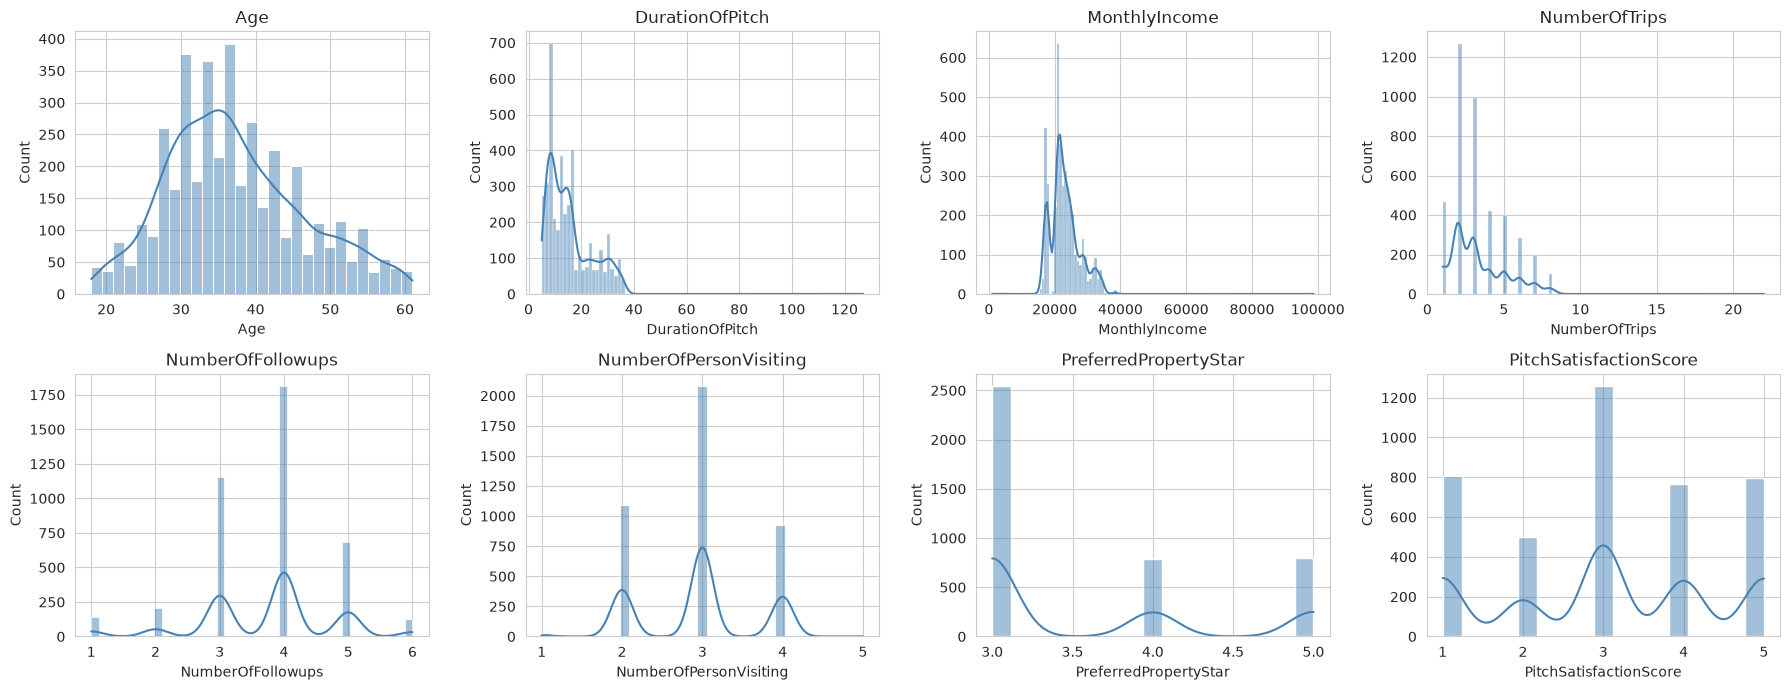

In [12]:
# Univariate analysis - numeric features
num_cols = ["Age", "DurationOfPitch", "MonthlyIncome", "NumberOfTrips",
            "NumberOfFollowups", "NumberOfPersonVisiting", "PreferredPropertyStar", "PitchSatisfactionScore"]
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for ax, col in zip(axes.flat, num_cols):
    sns.histplot(df[col], kde=True, ax=ax, color="steelblue")
    ax.set_title(col)
plt.tight_layout(); plt.show()

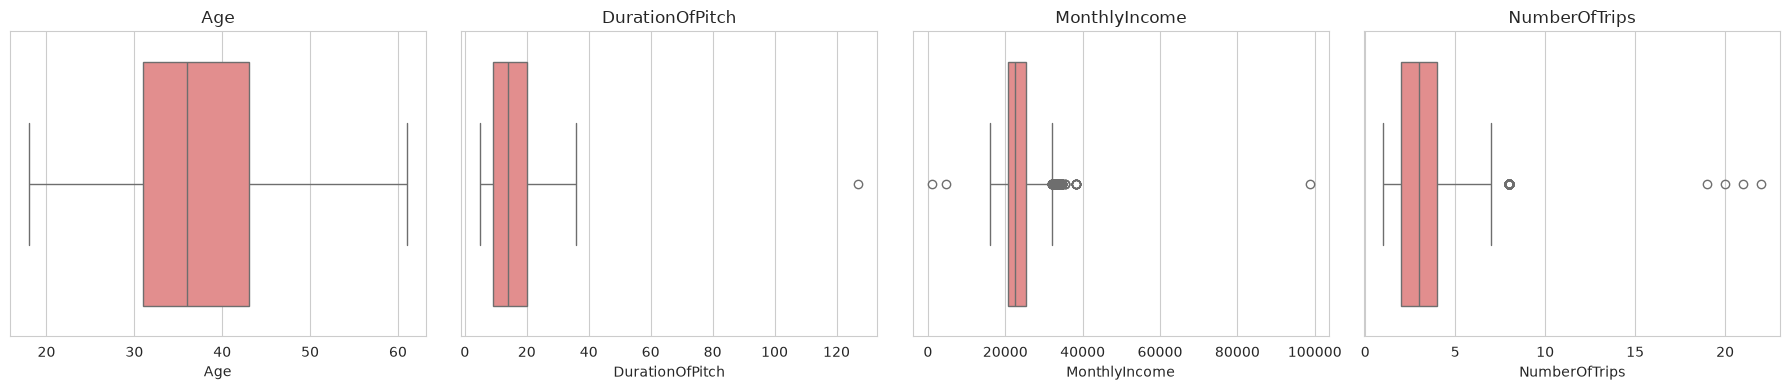

In [13]:
# Boxplots to spot outliers in the continuous features
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, col in zip(axes, ["Age", "DurationOfPitch", "MonthlyIncome", "NumberOfTrips"]):
    sns.boxplot(x=df[col], ax=ax, color="lightcoral"); ax.set_title(col)
plt.tight_layout(); plt.show()

**Observations**
- Age is fairly symmetric (mostly 26-50). `MonthlyIncome` and `DurationOfPitch` are right-skewed with a few extreme values (pitch durations above 100 minutes, incomes above 90k), and `NumberOfTrips` has a few customers with 19-22 trips a year.
- These extremes are rare and plausible, so I do not remove them. Tree-based models are not sensitive to outliers anyway.

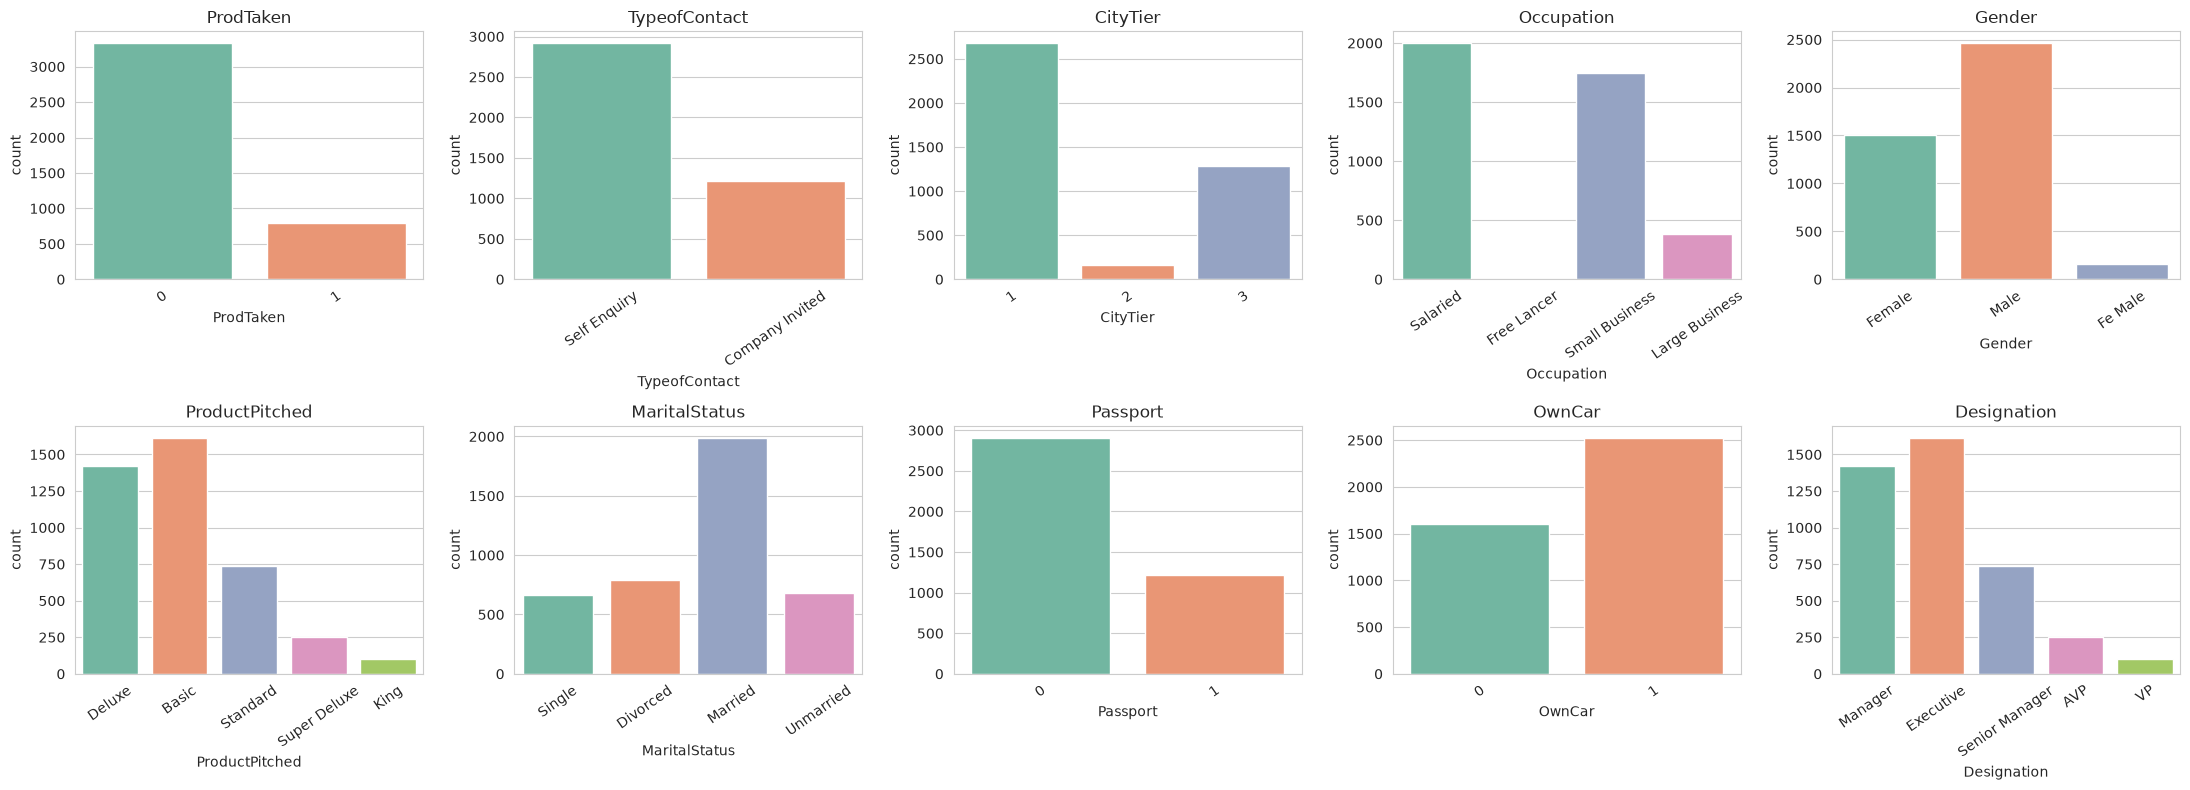

In [14]:
# Univariate analysis - categorical features and target
cat_cols = ["ProdTaken", "TypeofContact", "CityTier", "Occupation", "Gender", "ProductPitched",
            "MaritalStatus", "Passport", "OwnCar", "Designation"]
fig, axes = plt.subplots(2, 5, figsize=(22, 8))
for ax, col in zip(axes.flat, cat_cols):
    sns.countplot(x=df[col], ax=ax, palette="Set2")
    ax.set_title(col); ax.tick_params(axis="x", rotation=35)
plt.tight_layout(); plt.show()

**Observations**
- Most leads come through **Self Enquiry** (~71%), and most customers are from **Tier 1 cities**.
- **Basic** and **Deluxe** are pitched far more often than King or Super Deluxe.
- Only about 29% of customers hold a passport, while about 62% own a car.

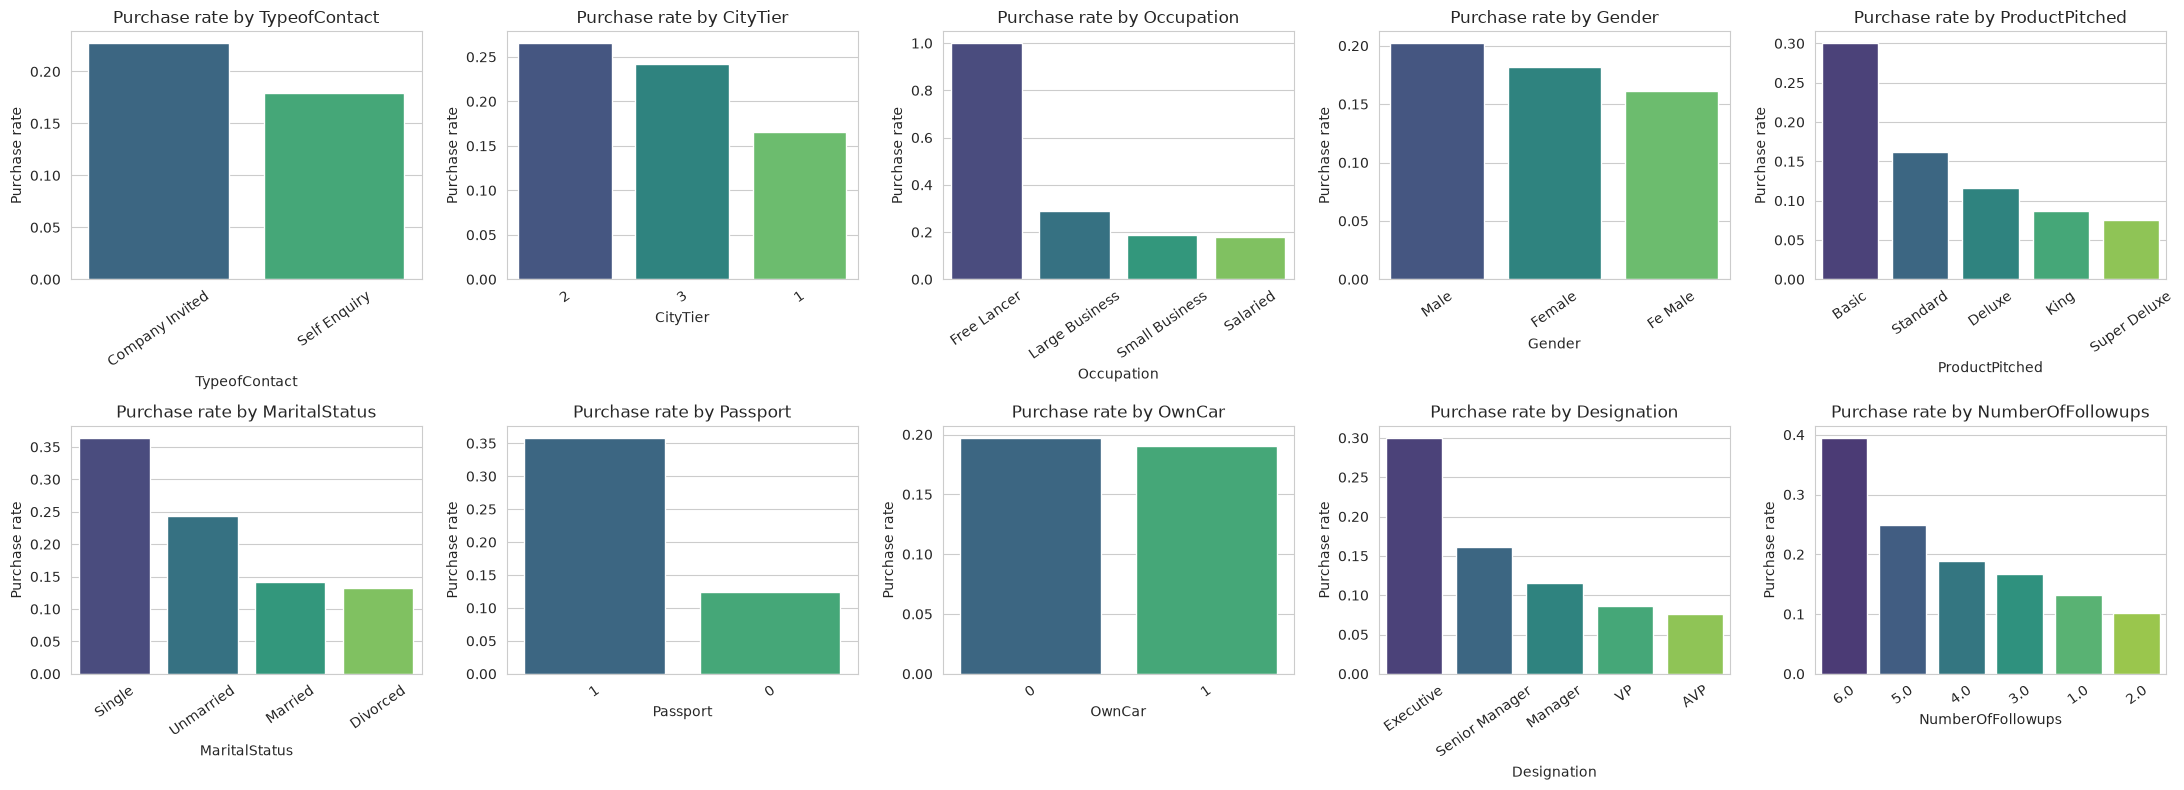

In [15]:
# Bivariate analysis - purchase rate by each categorical feature
fig, axes = plt.subplots(2, 5, figsize=(22, 8))
for ax, col in zip(axes.flat, cat_cols[1:] + ["NumberOfFollowups"]):
    rate = df.groupby(col)["ProdTaken"].mean().sort_values(ascending=False)
    sns.barplot(x=rate.index.astype(str), y=rate.values, ax=ax, palette="viridis")
    ax.set_title(f"Purchase rate by {col}"); ax.set_ylabel("Purchase rate"); ax.tick_params(axis="x", rotation=35)
plt.tight_layout(); plt.show()

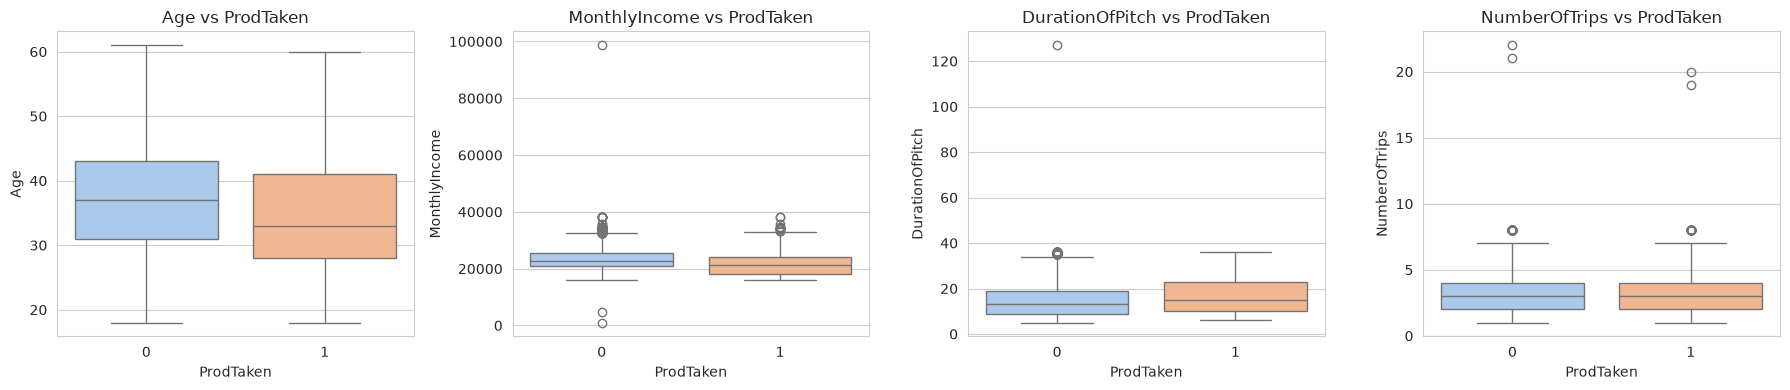

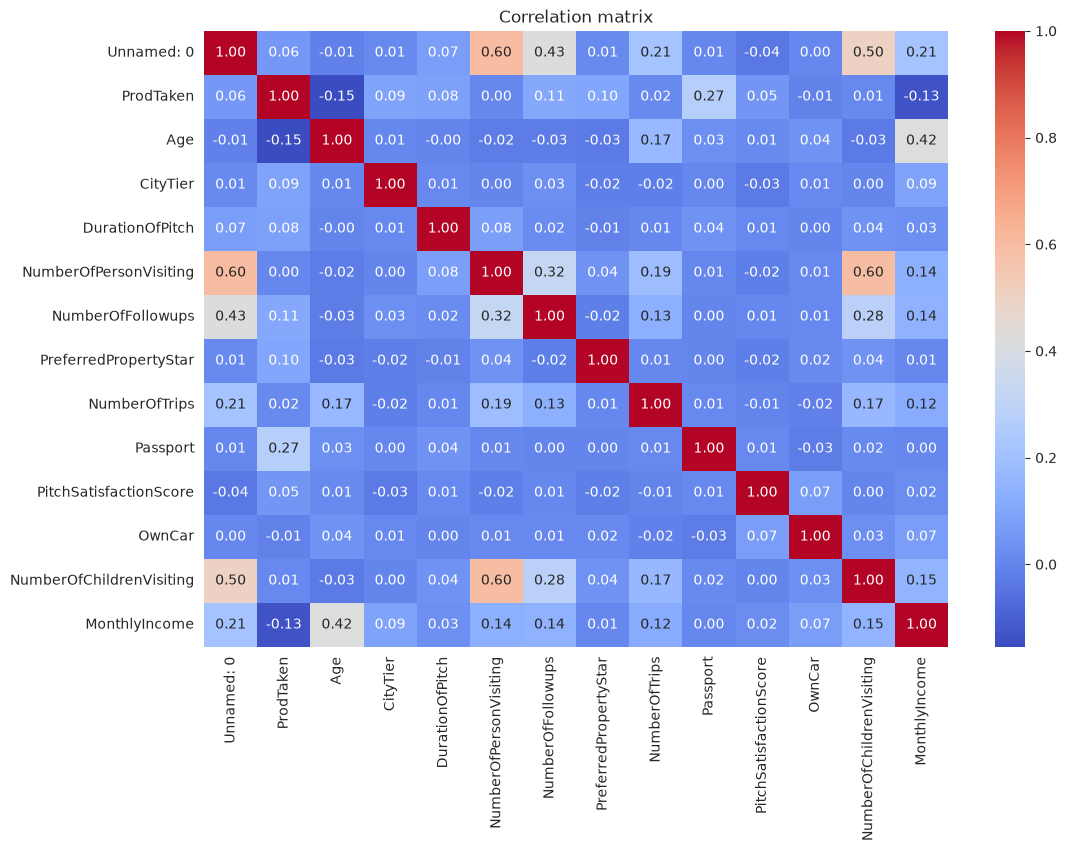

In [16]:
# Bivariate analysis - numeric features vs target
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, col in zip(axes, ["Age", "MonthlyIncome", "DurationOfPitch", "NumberOfTrips"]):
    sns.boxplot(x="ProdTaken", y=col, data=df, ax=ax, palette="pastel"); ax.set_title(f"{col} vs ProdTaken")
plt.tight_layout(); plt.show()

# Correlation heatmap of numeric features
plt.figure(figsize=(12, 8))
sns.heatmap(df.drop(columns=["CustomerID"]).select_dtypes("number").corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation matrix"); plt.show()

**Observations**
- **Passport** is the strongest single signal: customers with a passport buy at roughly 3x the rate of those without.
- **Basic** package pitches (to Executives) convert best, and conversion drops for Deluxe, Super Deluxe and King. The cheaper entry-level package sells more easily.
- Passport holders buy at **35.8%** against 12.4% for those without, almost 3x.
- **Single** customers (36%) and **Unmarried** (24%) convert far better than Married/Divorced (~14%). **Large Business** owners convert at 29%, and **Tier 2/3** cities (~25%) beat Tier 1 (16.5%).
- Conversion rises steadily with **follow-ups**, from about 13% with 1 follow-up to almost 40% with 6. Persistence pays.
- Buyers are slightly **younger** (median 33 vs 37) with slightly **lower incomes** (median ~21.3k vs ~22.8k), which fits the Basic package converting best.
- `NumberOfPersonVisiting` and `NumberOfChildrenVisiting` are correlated (~0.6), and Age and MonthlyIncome are moderately correlated, but nothing is high enough to cause problems for tree models.

In [17]:
# Data quality checks that drive the cleaning logic in prep.py
print("'Fe Male' rows:", (df["Gender"] == "Fe Male").sum())
dups = df.drop(columns=["CustomerID", df.columns[0]]).duplicated().sum()
print("Exact duplicate customer profiles (ignoring IDs):", dups)

'Fe Male' rows: 155
Exact duplicate customer profiles (ignoring IDs): 117


**Observations**
- Apart from the `Fe Male` typo, there are **117 rows that are exact copies** of another customer's profile once the IDs are ignored. If I keep them, the same record could end up in both train and test and inflate the test scores, so I drop them in prep.

## Data Preparation

In [18]:
%%writefile tourism_project/model_building/prep.py
"""Data preparation: load raw data from the repo, clean it, split it and save the splits locally.

Outputs (written to the working directory so the GitHub Actions job can upload them as an artifact):
    Xtrain.csv, Xtest.csv, ytrain.csv, ytest.csv
"""
import os
import pandas as pd
from sklearn.model_selection import train_test_split

DATA_PATH = os.path.join("tourism_project", "data", "tourism.csv")
TARGET = "ProdTaken"

# 1. Load the dataset directly from the repository data folder
df = pd.read_csv(DATA_PATH)
print("Raw shape:", df.shape)

# 2. Remove unnecessary columns
#    - the unnamed index column left over from an earlier export
#    - CustomerID is just an identifier and carries no predictive information
unnamed = [c for c in df.columns if c.startswith("Unnamed")]
df = df.drop(columns=unnamed + ["CustomerID"])
print("Dropped columns:", unnamed + ["CustomerID"])

# 3. Clean categorical values
df["Gender"] = df["Gender"].replace({"Fe Male": "Female"})      # fix typo
df["Occupation"] = df["Occupation"].replace({"Free Lancer": "Freelancer"})  # consistent spelling
for col in df.select_dtypes("object").columns:
    df[col] = df[col].str.strip()

# 4. Remove exact duplicate customer profiles (prevents train/test leakage)
before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"Removed {before - len(df)} duplicate rows")

# 5. Handle missing values defensively (current file has none, but new data may)
num_cols = df.select_dtypes("number").columns.drop(TARGET)
cat_cols = df.select_dtypes("object").columns
df[num_cols] = df[num_cols].fillna(df[num_cols].median())
df[cat_cols] = df[cat_cols].fillna(df[cat_cols].mode().iloc[0])
print("Missing values after cleaning:", int(df.isna().sum().sum()))

# 6. Split into features / target and into train / test (stratified to keep the ~19% purchase rate)
X = df.drop(columns=[TARGET])
y = df[TARGET]
Xtrain, Xtest, ytrain, ytest = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# 7. Save the splits locally - the workflow passes these to the training job as an artifact
Xtrain.to_csv("Xtrain.csv", index=False)
Xtest.to_csv("Xtest.csv", index=False)
ytrain.to_csv("ytrain.csv", index=False)
ytest.to_csv("ytest.csv", index=False)
print(f"Train: {Xtrain.shape} | Test: {Xtest.shape}")
print(f"Purchase rate - train: {ytrain.mean():.2%}, test: {ytest.mean():.2%}")
print("Saved Xtrain.csv, Xtest.csv, ytrain.csv, ytest.csv")

Overwriting tourism_project/model_building/prep.py


In [19]:
!python tourism_project/model_building/prep.py

Raw shape: (4128, 21)
Dropped columns: ['Unnamed: 0', 'CustomerID']
Removed 117 duplicate rows
Missing values after cleaning: 0
Train: (3208, 18) | Test: (803, 18)
Purchase rate - train: 19.30%, test: 19.30%
Saved Xtrain.csv, Xtest.csv, ytrain.csv, ytest.csv


**Observations**
- After dropping the index column and `CustomerID`, fixing `Fe Male` and removing the 117 duplicates, I have **4,011 clean rows and 18 features**.
- The stratified 80/20 split keeps the purchase rate the same in train and test, so evaluation reflects the real class balance.

## Model Selection (Development Experiment)

Before fixing the model in `train.py`, I compared the allowed algorithms on the same split with default-ish settings and class weighting. I used **recall and F1 for the purchase class** to choose, because missing a likely buyer (false negative) costs the company a sale, while an extra call to a non-buyer (false positive) only costs some sales effort.

In [20]:
# Load the splits produced by prep.py
Xtrain = pd.read_csv("Xtrain.csv"); Xtest = pd.read_csv("Xtest.csv")
ytrain = pd.read_csv("ytrain.csv").squeeze(); ytest = pd.read_csv("ytest.csv").squeeze()

numeric_features = Xtrain.select_dtypes("number").columns.tolist()
categorical_features = Xtrain.select_dtypes("object").columns.tolist()
preprocessor = make_column_transformer(
    (StandardScaler(), numeric_features),
    (OneHotEncoder(handle_unknown="ignore"), categorical_features),
)
spw = (ytrain == 0).sum() / (ytrain == 1).sum()   # ratio used to up-weight the minority class

candidates = {
    "Decision Tree": DecisionTreeClassifier(class_weight="balanced", max_depth=6, random_state=42),
    "Bagging": BaggingClassifier(n_estimators=100, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, class_weight="balanced", random_state=42),
    "AdaBoost": AdaBoostClassifier(n_estimators=200, random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=200, random_state=42),
    "XGBoost": xgb.XGBClassifier(n_estimators=200, scale_pos_weight=spw, eval_metric="logloss", random_state=42),
}
rows = []
for name, est in candidates.items():
    pipe = make_pipeline(preprocessor, est).fit(Xtrain, ytrain)
    for split, X_, y_ in [("Train", Xtrain, ytrain), ("Test", Xtest, ytest)]:
        p = pipe.predict(X_)
        rows.append({"Model": name, "Split": split, "Accuracy": accuracy_score(y_, p),
                     "Recall": recall_score(y_, p), "Precision": precision_score(y_, p), "F1": f1_score(y_, p)})
comparison = pd.DataFrame(rows).pivot(index="Model", columns="Split", values=["Recall", "F1", "Precision", "Accuracy"]).round(3)
comparison.sort_values(("F1", "Test"), ascending=False)

Recall            F1        Precision        Accuracy       
Split               Test  Train   Test  Train      Test  Train     Test  Train
Model                                                                         
XGBoost            0.761  1.000  0.800  1.000     0.843  1.000    0.927  1.000
Bagging            0.703  1.000  0.793  1.000     0.908  1.000    0.929  1.000
Random Forest      0.510  1.000  0.661  1.000     0.940  1.000    0.899  1.000
Gradient Boosting  0.471  0.638  0.598  0.758     0.820  0.934    0.878  0.921
Decision Tree      0.787  0.869  0.561  0.617     0.436  0.478    0.762  0.791
AdaBoost           0.265  0.339  0.383  0.471     0.695  0.769    0.836  0.853

**Observations**
- Bagging, Random Forest and XGBoost all score 1.0 on train, so they memorise the training data before any tuning. Random Forest catches only about half of the buyers (recall 0.51) despite its high precision.
- The Decision Tree has a high recall (0.79), but its precision is only 0.44, so more than half of the people it would call are not buyers.
- AdaBoost (recall 0.27) and Gradient Boosting (recall 0.47) miss most buyers with default settings.
- **XGBoost** with `scale_pos_weight` gives the best test F1 (0.80) with recall 0.76. Bagging is a close second but cannot weight the minority class directly, and it has the regularisation knobs (`max_depth`, `reg_lambda`, `colsample_bytree`) to control overfitting. I chose XGBoost for the pipeline and tuned it with GridSearchCV in `train.py`.

## Model Training and Registration with Experimentation Tracking

In [21]:
%%writefile tourism_project/model_building/train.py
"""Model training with experiment tracking.

- loads the train/test splits produced by the data-prep job (downloaded as a workflow artifact)
- defines an XGBoost pipeline and a hyperparameter grid, tunes it with GridSearchCV
- logs every tuned parameter combination and the final metrics to MLflow
- evaluates the best model and saves it to tourism_project/deployment/ so the workflow can commit it
"""
import os
import json
import joblib
import mlflow
import pandas as pd
import xgboost as xgb
from sklearn.compose import make_column_transformer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import (classification_report, accuracy_score, precision_score,
                             recall_score, f1_score, roc_auc_score)

# MLflow tracking: the GitHub Actions job starts a server on localhost:5000.
# When run elsewhere, MLFLOW_TRACKING_URI can point to any store (e.g. file:./mlruns).
mlflow.set_tracking_uri(os.getenv("MLFLOW_TRACKING_URI", "http://localhost:5000"))
mlflow.set_experiment("tourism-wellness-package")

MODEL_DIR = os.path.join("tourism_project", "deployment")
MODEL_PATH = os.path.join(MODEL_DIR, "best_tourism_model_v1.joblib")
CLASSIFICATION_THRESHOLD = 0.45   # slightly below 0.5 to favour recall on likely buyers

# 1. Load the splits from the workflow artifact
Xtrain = pd.read_csv("Xtrain.csv")
Xtest = pd.read_csv("Xtest.csv")
ytrain = pd.read_csv("ytrain.csv").squeeze()
ytest = pd.read_csv("ytest.csv").squeeze()

# 2. Preprocessing: scale numeric features, one-hot encode categorical ones
numeric_features = Xtrain.select_dtypes("number").columns.tolist()
categorical_features = Xtrain.select_dtypes("object").columns.tolist()
preprocessor = make_column_transformer(
    (StandardScaler(), numeric_features),
    (OneHotEncoder(handle_unknown="ignore"), categorical_features),
)

# 3. Model: XGBoost, with scale_pos_weight to handle the ~19% / 81% class imbalance
scale_pos_weight = (ytrain == 0).sum() / (ytrain == 1).sum()
xgb_model = xgb.XGBClassifier(scale_pos_weight=scale_pos_weight, eval_metric="logloss",
                              random_state=42, n_jobs=-1)
model_pipeline = make_pipeline(preprocessor, xgb_model)

# 4. Hyperparameter grid
param_grid = {
    "xgbclassifier__n_estimators": [100, 200],
    "xgbclassifier__max_depth": [3, 5, 7],
    "xgbclassifier__learning_rate": [0.05, 0.1],
    "xgbclassifier__colsample_bytree": [0.6, 0.8],
    "xgbclassifier__reg_lambda": [1, 5],
}

with mlflow.start_run(run_name="xgb-gridsearch"):
    # 5. Tune with 5-fold stratified CV, optimising F1 of the purchase class
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    grid = GridSearchCV(model_pipeline, param_grid, cv=cv, scoring="f1", n_jobs=-1)
    grid.fit(Xtrain, ytrain)

    # 6. Log every tuned parameter combination as a nested run
    res = grid.cv_results_
    for i in range(len(res["params"])):
        with mlflow.start_run(run_name=f"combo_{i}", nested=True):
            mlflow.log_params(res["params"][i])
            mlflow.log_metric("mean_cv_f1", res["mean_test_score"][i])
            mlflow.log_metric("std_cv_f1", res["std_test_score"][i])

    # 7. Log the best parameters
    mlflow.log_params(grid.best_params_)
    mlflow.log_param("scale_pos_weight", round(float(scale_pos_weight), 3))
    mlflow.log_param("classification_threshold", CLASSIFICATION_THRESHOLD)
    print("Combinations tried:", len(res["params"]))
    print("Best params:", grid.best_params_)
    print(f"Best CV F1: {grid.best_score_:.4f}")

    # 8. Evaluate the best model on train and test using the chosen threshold
    best_model = grid.best_estimator_
    metrics = {}
    for split, X_, y_ in [("train", Xtrain, ytrain), ("test", Xtest, ytest)]:
        proba = best_model.predict_proba(X_)[:, 1]
        pred = (proba >= CLASSIFICATION_THRESHOLD).astype(int)
        metrics.update({
            f"{split}_accuracy": accuracy_score(y_, pred),
            f"{split}_precision": precision_score(y_, pred),
            f"{split}_recall": recall_score(y_, pred),
            f"{split}_f1": f1_score(y_, pred),
            f"{split}_roc_auc": roc_auc_score(y_, proba),
        })
        print(f"\n--- {split.upper()} classification report (threshold={CLASSIFICATION_THRESHOLD}) ---")
        print(classification_report(y_, pred, digits=3))
    mlflow.log_metrics(metrics)

    # 9. Save the best model so the pipeline can commit it to the repository
    os.makedirs(MODEL_DIR, exist_ok=True)
    joblib.dump(best_model, MODEL_PATH)
    with open(os.path.join(MODEL_DIR, "model_metrics.json"), "w") as f:
        json.dump({"best_params": grid.best_params_, "threshold": CLASSIFICATION_THRESHOLD,
                   **{k: round(v, 4) for k, v in metrics.items()}}, f, indent=2)
    mlflow.log_artifact(MODEL_PATH, artifact_path="model")
    print("\nSaved best model to", MODEL_PATH)

Overwriting tourism_project/model_building/train.py


For this local run I point MLflow to a file store (`./mlruns`). In GitHub Actions the same script logs to the MLflow server the workflow starts on port 5000.

In [22]:
# Run the training script exactly as the pipeline does, with a local MLflow store
import shutil; shutil.rmtree("mlruns", ignore_errors=True)   # start from a clean local tracking store
os.environ["MLFLOW_TRACKING_URI"] = "file:./mlruns"
!python tourism_project/model_building/train.py

2026/10/31 15:18:45 INFO mlflow.tracking.fluent: Experiment with name 'tourism-wellness-package' does not exist. Creating a new experiment.


Combinations tried: 48
Best params: {'xgbclassifier__colsample_bytree': 0.6, 'xgbclassifier__learning_rate': 0.1, 'xgbclassifier__max_depth': 7, 'xgbclassifier__n_estimators': 200, 'xgbclassifier__reg_lambda': 1}
Best CV F1: 0.7858

--- TRAIN classification report (threshold=0.45) ---
              precision    recall  f1-score   support

           0      1.000     1.000     1.000      2589
           1      1.000     1.000     1.000       619

    accuracy                          1.000      3208
   macro avg      1.000     1.000     1.000      3208
weighted avg      1.000     1.000     1.000      3208


--- TEST classification report (threshold=0.45) ---
              precision    recall  f1-score   support

           0      0.957     0.968     0.962       648
           1      0.858     0.819     0.838       155

    accuracy                          0.939       803
   macro avg      0.908     0.893     0.900       803
weighted avg      0.938     0.939     0.938       803


Saved 

In [23]:
# Experiment tracking: read back what was logged to MLflow
mlflow.set_tracking_uri("file:./mlruns")
runs = mlflow.search_runs(experiment_names=["tourism-wellness-package"])
param_cols = [c for c in runs.columns if c.startswith("params.xgbclassifier")]
nested = runs[runs["tags.mlflow.runName"].str.startswith("combo_")]
print("Runs logged (1 parent + nested):", len(runs))
nested[param_cols + ["metrics.mean_cv_f1"]].sort_values("metrics.mean_cv_f1", ascending=False).head(10)

Runs logged (1 parent + nested): 49


,params.xgbclassifier__colsample_bytree,params.xgbclassifier__n_estimators,params.xgbclassifier__reg_lambda,params.xgbclassifier__max_depth,params.xgbclassifier__learning_rate,metrics.mean_cv_f1
25,0.6,200,1,7,0.1,0.785790
27,0.6,100,1,7,0.1,0.778321
1,0.8,200,1,7,0.1,0.778052
13,0.8,200,1,7,0.05,0.774993
3,0.8,100,1,7,0.1,0.774310
24,0.6,200,5,7,0.1,0.769308
0,0.8,200,5,7,0.1,0.766629
12,0.8,200,5,7,0.05,0.763751
36,0.6,200,5,7,0.05,0.762789
37,0.6,200,1,7,0.05,0.760328


**Observations**
- All **48 parameter combinations** were logged to MLflow as nested runs under one parent run (49 runs in total), each with its mean and std CV F1. The best parameters and the final train/test metrics are logged on the parent run.
- Best combination: `max_depth=7, n_estimators=200, learning_rate=0.1, colsample_bytree=0.6, reg_lambda=1`, with a **CV F1 of 0.786**. Deeper trees and the higher learning rate consistently ranked at the top, and the top 10 combinations are all within about 0.01 F1 of each other, so the result is stable.

## Best Model Evaluation

,Accuracy,Recall,Precision,F1,ROC-AUC
Tuned XGBoost (test),0.939,0.819,0.858,0.838,0.96


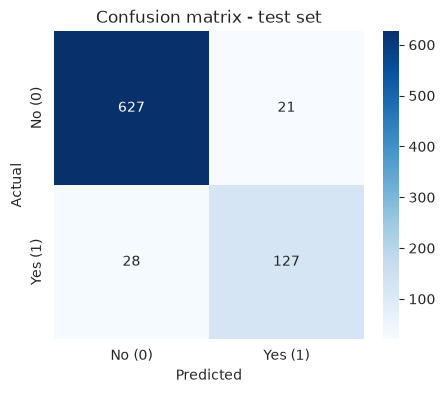

In [24]:
# Load the saved model (the same artifact the pipeline commits and the app loads)
best_model = joblib.load("tourism_project/deployment/best_tourism_model_v1.joblib")
THRESHOLD = 0.45
proba = best_model.predict_proba(Xtest)[:, 1]
y_pred = (proba >= THRESHOLD).astype(int)

final = pd.DataFrame({
    "Accuracy": [accuracy_score(ytest, y_pred)], "Recall": [recall_score(ytest, y_pred)],
    "Precision": [precision_score(ytest, y_pred)], "F1": [f1_score(ytest, y_pred)],
    "ROC-AUC": [roc_auc_score(ytest, proba)]}, index=["Tuned XGBoost (test)"]).round(3)
display(final)

# Confusion matrix
cm = confusion_matrix(ytest, y_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["No (0)", "Yes (1)"], yticklabels=["No (0)", "Yes (1)"])
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title("Confusion matrix - test set"); plt.show()

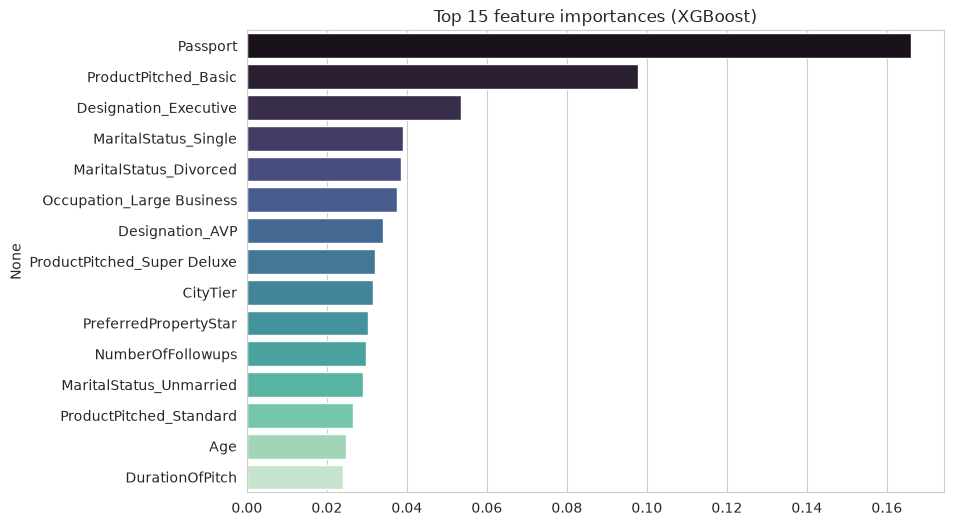

In [25]:
# Feature importance from the XGBoost step, mapped back to the one-hot feature names
pre = best_model.named_steps["columntransformer"]
clf = best_model.named_steps["xgbclassifier"]
names = [n.split("__", 1)[1] for n in pre.get_feature_names_out()]
imp = pd.Series(clf.feature_importances_, index=names).sort_values(ascending=False).head(15)
plt.figure(figsize=(9, 6)); sns.barplot(x=imp.values, y=imp.index, palette="mako")
plt.title("Top 15 feature importances (XGBoost)"); plt.show()

**Observations - best model (tuned XGBoost, threshold 0.45, 803 test customers)**
- **Recall 0.819**: the model finds 127 of the 155 actual buyers and misses only 28.
- **Precision 0.858**: of the 148 customers it flags, 127 really buy, so only 21 calls go to non-buyers.
- **F1 0.838, accuracy 0.939, ROC-AUC 0.960.** Compared with untuned XGBoost (F1 0.800, recall 0.761), tuning plus the 0.45 threshold improved both recall and F1.
- The model still fits the training data perfectly (train F1 1.0), while CV F1 is 0.786 and test F1 is 0.838. The gap shows some overfitting, but the cross-validated and held-out scores agree, so its performance on new customers is reliable. Adding shallower trees or `min_child_weight` to the grid in the next pipeline run would be my next step to reduce the gap.
- **Feature importance:** `Passport` is by far the most important feature, followed by `ProductPitched_Basic` / `Designation_Executive` (the same segment), marital status (Single/Divorced), Large Business occupation, CityTier and preferred property star. This matches what I saw in the EDA.

# Deployment

In [26]:
os.makedirs("tourism_project/deployment", exist_ok=True)

## Streamlit App

In [27]:
%%writefile tourism_project/deployment/app.py
"""Streamlit front end for the Wellness Tourism Package purchase prediction model.

Loads the model that the GitHub Actions pipeline commits to tourism_project/deployment/,
collects customer details, puts them into a DataFrame and shows the prediction.
"""
import os
import joblib
import pandas as pd
import streamlit as st

MODEL_PATH = os.path.join(os.path.dirname(__file__), "best_tourism_model_v1.joblib")
THRESHOLD = 0.45  # same threshold used during evaluation

@st.cache_resource
def load_model():
    return joblib.load(MODEL_PATH)

model = load_model()

st.title("Visit with Us - Wellness Tourism Package Predictor")
st.write("Enter the customer details below to estimate whether they are likely to buy the "
         "Wellness Tourism Package before the sales team contacts them.")

# ---- Customer details ----
st.subheader("Customer details")
col1, col2 = st.columns(2)
with col1:
    age = st.number_input("Age", min_value=18, max_value=100, value=35)
    gender = st.selectbox("Gender", ["Male", "Female"])
    marital = st.selectbox("Marital Status", ["Married", "Single", "Unmarried", "Divorced"])
    occupation = st.selectbox("Occupation", ["Salaried", "Small Business", "Large Business", "Freelancer"])
    designation = st.selectbox("Designation", ["Executive", "Manager", "Senior Manager", "AVP", "VP"])
    income = st.number_input("Monthly Income", min_value=0.0, value=22000.0, step=500.0)
    city_tier = st.selectbox("City Tier", [1, 2, 3])
with col2:
    passport = st.selectbox("Has a valid passport?", ["Yes", "No"])
    own_car = st.selectbox("Owns a car?", ["Yes", "No"])
    trips = st.number_input("Average trips per year", min_value=0, max_value=30, value=3)
    persons = st.number_input("Number of persons visiting", min_value=1, max_value=10, value=3)
    children = st.number_input("Children (below 5) visiting", min_value=0, max_value=5, value=1)
    property_star = st.selectbox("Preferred property star", [3, 4, 5])

# ---- Interaction details ----
st.subheader("Sales interaction")
col3, col4 = st.columns(2)
with col3:
    contact = st.selectbox("Type of contact", ["Self Enquiry", "Company Invited"])
    product = st.selectbox("Product pitched", ["Basic", "Standard", "Deluxe", "Super Deluxe", "King"])
    duration = st.number_input("Duration of pitch (minutes)", min_value=0, max_value=200, value=15)
with col4:
    followups = st.number_input("Number of follow-ups", min_value=0, max_value=10, value=3)
    satisfaction = st.slider("Pitch satisfaction score", 1, 5, 3)

# ---- Collect the inputs into a DataFrame with the same columns used in training ----
input_df = pd.DataFrame([{
    "Age": age, "TypeofContact": contact, "CityTier": city_tier, "DurationOfPitch": duration,
    "Occupation": occupation, "Gender": gender, "NumberOfPersonVisiting": persons,
    "NumberOfFollowups": followups, "ProductPitched": product, "PreferredPropertyStar": property_star,
    "MaritalStatus": marital, "NumberOfTrips": trips, "Passport": 1 if passport == "Yes" else 0,
    "PitchSatisfactionScore": satisfaction, "OwnCar": 1 if own_car == "Yes" else 0,
    "NumberOfChildrenVisiting": children, "Designation": designation, "MonthlyIncome": income,
}])

with st.expander("Input data sent to the model"):
    st.dataframe(input_df)

if st.button("Predict"):
    proba = model.predict_proba(input_df)[0, 1]
    if proba >= THRESHOLD:
        st.success(f"Likely to purchase the Wellness Tourism Package (probability {proba:.1%}). Prioritise this customer.")
    else:
        st.warning(f"Unlikely to purchase (probability {proba:.1%}). Lower priority for this campaign.")

Overwriting tourism_project/deployment/app.py


## App Dependencies

In [28]:
%%writefile tourism_project/deployment/requirements.txt
pandas==2.2.3
scikit-learn==1.6.1
xgboost==2.1.4
joblib==1.6.0
streamlit==1.44.1

Overwriting tourism_project/deployment/requirements.txt


In [29]:
# Smoke test: start the Streamlit app headless for a few seconds and confirm it serves and loads the model
import subprocess, time, urllib.request
proc = subprocess.Popen(["streamlit", "run", "tourism_project/deployment/app.py", "--server.headless", "true",
                         "--server.port", "8599"], stdout=subprocess.PIPE, stderr=subprocess.STDOUT)
time.sleep(12)
print("Health check:", urllib.request.urlopen("http://localhost:8599/_stcore/health").read().decode())
proc.terminate(); out = proc.communicate(timeout=10)[0].decode()
print("Errors in app log:", "Traceback" in out)

# Same check from Python: the app's input DataFrame format gives a valid prediction
sample = Xtest.iloc[[0]]
print("Sample prediction probability:", round(float(best_model.predict_proba(sample)[0, 1]), 3))

Health check: ok
Errors in app log: False
Sample prediction probability: 0.953


The app starts cleanly (health check `ok`, no tracebacks) and the model accepts a single-row DataFrame in the same format the app builds.

# MLOps Pipeline with Github Actions Workflow

In [30]:
os.makedirs(".github/workflows", exist_ok=True)

In [31]:
%%writefile .github/workflows/pipeline.yml
name: Tourism Project Pipeline

on:
  push:
    branches:
      - main  # Automatically triggers on push to the main branch
  workflow_dispatch:  # lets you click "Run workflow" in the Actions tab

permissions:
  contents: write   # lets the workflow commit the trained model back to main

jobs:

  register-dataset:
    runs-on: ubuntu-latest
    steps:
      - uses: actions/checkout@v4
      - uses: actions/setup-python@v5
        with:
          python-version: "3.11"
      - name: Install Dependencies
        run: pip install -r tourism_project/requirements.txt
      - name: Register Dataset
        run: python tourism_project/model_building/data_register.py
      - name: Upload Registered Dataset
        uses: actions/upload-artifact@v4
        with:
          name: registered-data
          path: tourism_project/data/tourism.csv

  data-prep:
    needs: register-dataset
    runs-on: ubuntu-latest
    steps:
      - uses: actions/checkout@v4
      - uses: actions/setup-python@v5
        with:
          python-version: "3.11"
      - name: Install Dependencies
        run: pip install -r tourism_project/requirements.txt
      - name: Run Data Preparation
        run: python tourism_project/model_building/prep.py
      - name: Upload Train Test Splits
        uses: actions/upload-artifact@v4
        with:
          name: data-splits
          path: |
            Xtrain.csv
            Xtest.csv
            ytrain.csv
            ytest.csv

  model-traning:
    needs: data-prep
    runs-on: ubuntu-latest
    steps:
      - uses: actions/checkout@v4
      - uses: actions/setup-python@v5
        with:
          python-version: "3.11"
      - name: Install Dependencies
        run: pip install -r tourism_project/requirements.txt
      - name: Download Train Test Splits
        uses: actions/download-artifact@v4
        with:
          name: data-splits
      - name: Start MLflow Server
        run: |
          nohup mlflow ui --host 0.0.0.0 --port 5000 &  # Run MLflow UI in the background
          sleep 5  # Wait for a moment to let the server starts
      - name: Model Building
        env:
          MLFLOW_TRACKING_URI: http://localhost:5000
        run: python tourism_project/model_building/train.py
      - name: Commit Trained Model
        run: |
          git config user.name "github-actions[bot]"
          git config user.email "github-actions[bot]@users.noreply.github.com"
          git add tourism_project/deployment/best_tourism_model_v1.joblib tourism_project/deployment/model_metrics.json   # path to the saved model file
          git commit -m "Add trained model [skip ci]" || echo "No changes to commit"
          git pull --rebase origin main
          git push origin HEAD:main

Overwriting .github/workflows/pipeline.yml


The workflow has three jobs that run in order: `register-dataset` → `data-prep` → `model-traning` (the job name is kept from the course template). The train/test splits move from `data-prep` to `model-traning` as the **data-splits** artifact. The last step commits the trained model back to `main`. The `[skip ci]` tag stops that commit from triggering the pipeline again in a loop.

## Requirements file for the Github Actions Workflow

In [32]:
%%writefile tourism_project/requirements.txt
pandas==2.2.3
numpy<2.3
scikit-learn==1.6.1
xgboost==2.1.4
mlflow==3.1.0
joblib==1.6.0

Overwriting tourism_project/requirements.txt


In [33]:
%%writefile .gitignore
# local artefacts that the pipeline regenerates
mlruns/
mlartifacts/
Xtrain.csv
Xtest.csv
ytrain.csv
ytest.csv
__pycache__/
.ipynb_checkpoints/

Overwriting .gitignore


In [34]:
# Local dry-run of the whole pipeline in the same order as the GitHub Actions jobs
os.environ["MLFLOW_TRACKING_URI"] = "file:./mlruns"
!python tourism_project/model_building/data_register.py > /dev/null && echo "register-dataset: OK"
!python tourism_project/model_building/prep.py > /dev/null && echo "data-prep: OK"
!python tourism_project/model_building/train.py > /dev/null && echo "model-traning: OK"
!find tourism_project .github -type f | sort

register-dataset: OK


data-prep: OK


model-traning: OK


.github/workflows/pipeline.yml
tourism_project/data/tourism.csv
tourism_project/deployment/app.py
tourism_project/deployment/best_tourism_model_v1.joblib
tourism_project/deployment/model_metrics.json
tourism_project/deployment/requirements.txt
tourism_project/model_building/data_register.py
tourism_project/model_building/prep.py
tourism_project/model_building/train.py
tourism_project/requirements.txt


## Github Authentication and Push Files

In [35]:
# NOTE: I pushed this repository to GitHub with git (gh CLI), so the PyGithub upload below is kept
# for reference and only runs when PUSH_WITH_PYGITHUB is switched on and a token is available.
PUSH_WITH_PYGITHUB = False

# --- Safety check: Verify that the dataset exists before pushing ---
CSV_LOCAL = "tourism_project/data/tourism.csv"

assert os.path.exists(CSV_LOCAL), (
    f"{CSV_LOCAL} not found. Please upload tourism.csv into the "
    "tourism_project/data/ folder before running this cell."
)

print("Dataset found:", CSV_LOCAL)
print("Repository already pushed with git:", f"https://github.com/{REPO}")

if PUSH_WITH_PYGITHUB and os.environ.get("GH_TOKEN"):
    gh = Github(os.environ["GH_TOKEN"])
    user = gh.get_user()
    REPO = f"{user.login}/{REPO_NAME}" # Define REPO using user.login and REPO_NAME

    # Create the repository if it does not already exist
    try:
        repo = gh.get_repo(REPO)
        print("Repository already exists:", repo.full_name)
    except GithubException:
        repo = user.create_repo(
            REPO_NAME,
            private=False,      # Change to True if you want a private repository
            auto_init=True      # Creates an initial README so the main branch exists
        )
        print("Repository created:", repo.full_name)

    # --- Push local folders to GitHub while preserving the folder structure ---
    # tourism_project/ -> Project source code, data, model building, deployment files
    # .github/         -> GitHub Actions workflow

    def push_folder(local_dir):
        for root, _, files in os.walk(local_dir):
            for fname in files:
                local_path = os.path.join(root, fname)
                repo_path = local_path
                content = open(local_path, "rb").read()

                try:
                    sha = repo.get_contents(repo_path, ref=BRANCH).sha
                    repo.update_file(
                        repo_path,
                        f"update {repo_path}",
                        content,
                        sha,
                        branch=BRANCH
                    )
                    print("updated", repo_path)

                except GithubException:
                    repo.create_file(
                        repo_path,
                        f"add {repo_path}",
                        content,
                        branch=BRANCH
                    )
                    print("added  ", repo_path)

    # Push project files
    push_folder("tourism_project")

    # Push GitHub Actions workflow
    push_folder(".github")

    # --- Verify that all required files exist in the repository ---
    print("\nVerifying repository structure...")

    required = [
        "tourism_project/requirements.txt",
        "tourism_project/model_building/data_register.py",
        "tourism_project/model_building/prep.py",
        "tourism_project/model_building/train.py",
        "tourism_project/data/tourism.csv",
        "tourism_project/deployment/app.py",
        "tourism_project/deployment/requirements.txt",
        ".github/workflows/pipeline.yml",
    ]

    all_ok = True

    for file in required:
        try:
            repo.get_contents(file, ref=BRANCH)
            print("✓", file)
        except GithubException:
            print("✗ Missing:", file)
            all_ok = False

    if all_ok:
        print("\nAll project files have been successfully pushed to GitHub.")
    else:
        print("\nSome files are missing. Please review the messages above.")

Dataset found: tourism_project/data/tourism.csv
Repository already pushed with git: https://github.com/rakesh1308/tourism-wellness-mlops


# Deploy the App on Streamlit Community Cloud

After the pipeline finishes, the trained model is committed to `tourism_project/deployment/`. Deploy the app as follows:

1. Go to **https://share.streamlit.io** and sign in with the GitHub account that owns the repository.
2. Click **Create app**.
3. Set:
   - **Repository:** `rakesh1308/tourism-wellness-mlops`
   - **Branch:** `main`
   - **Main file path:** `tourism_project/deployment/app.py`
4. Open **Advanced settings** and set **Python version** to **3.11** so the saved model loads with the same library versions used during training.
5. Click **Deploy**.

Streamlit installs the packages from `tourism_project/deployment/requirements.txt` and launches the app at a public `...streamlit.app` URL. My app is live at https://wellness-tourism-mlops-rakesh.streamlit.app/ (link and screenshot in the Output Evaluation section below).

# Output Evaluation

## GitHub
- **Repository:** https://github.com/rakesh1308/tourism-wellness-mlops
- **Successful workflow run:** https://github.com/rakesh1308/tourism-wellness-mlops/actions/runs/41189168388

**Repository root**

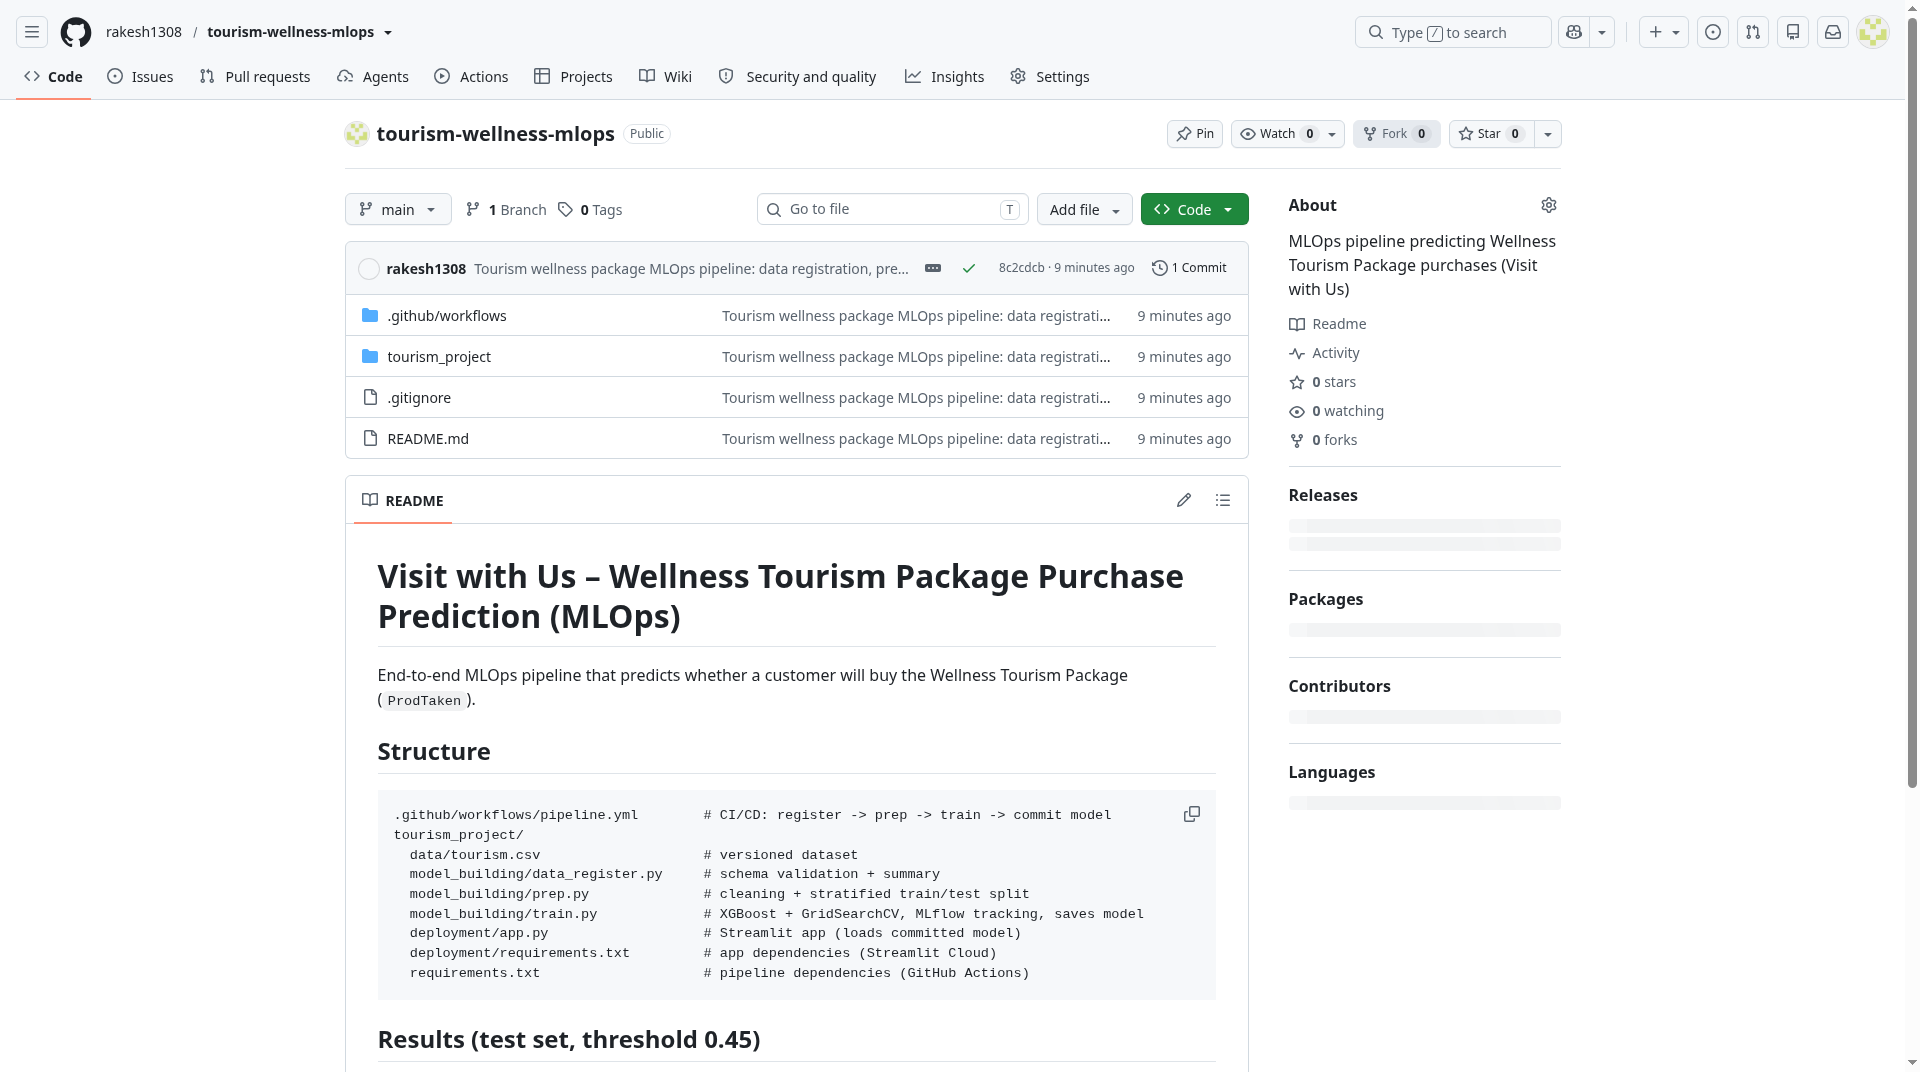

*The repo root has the `.github/workflows` pipeline, the `tourism_project` master folder and the README.*

**Folder structure**

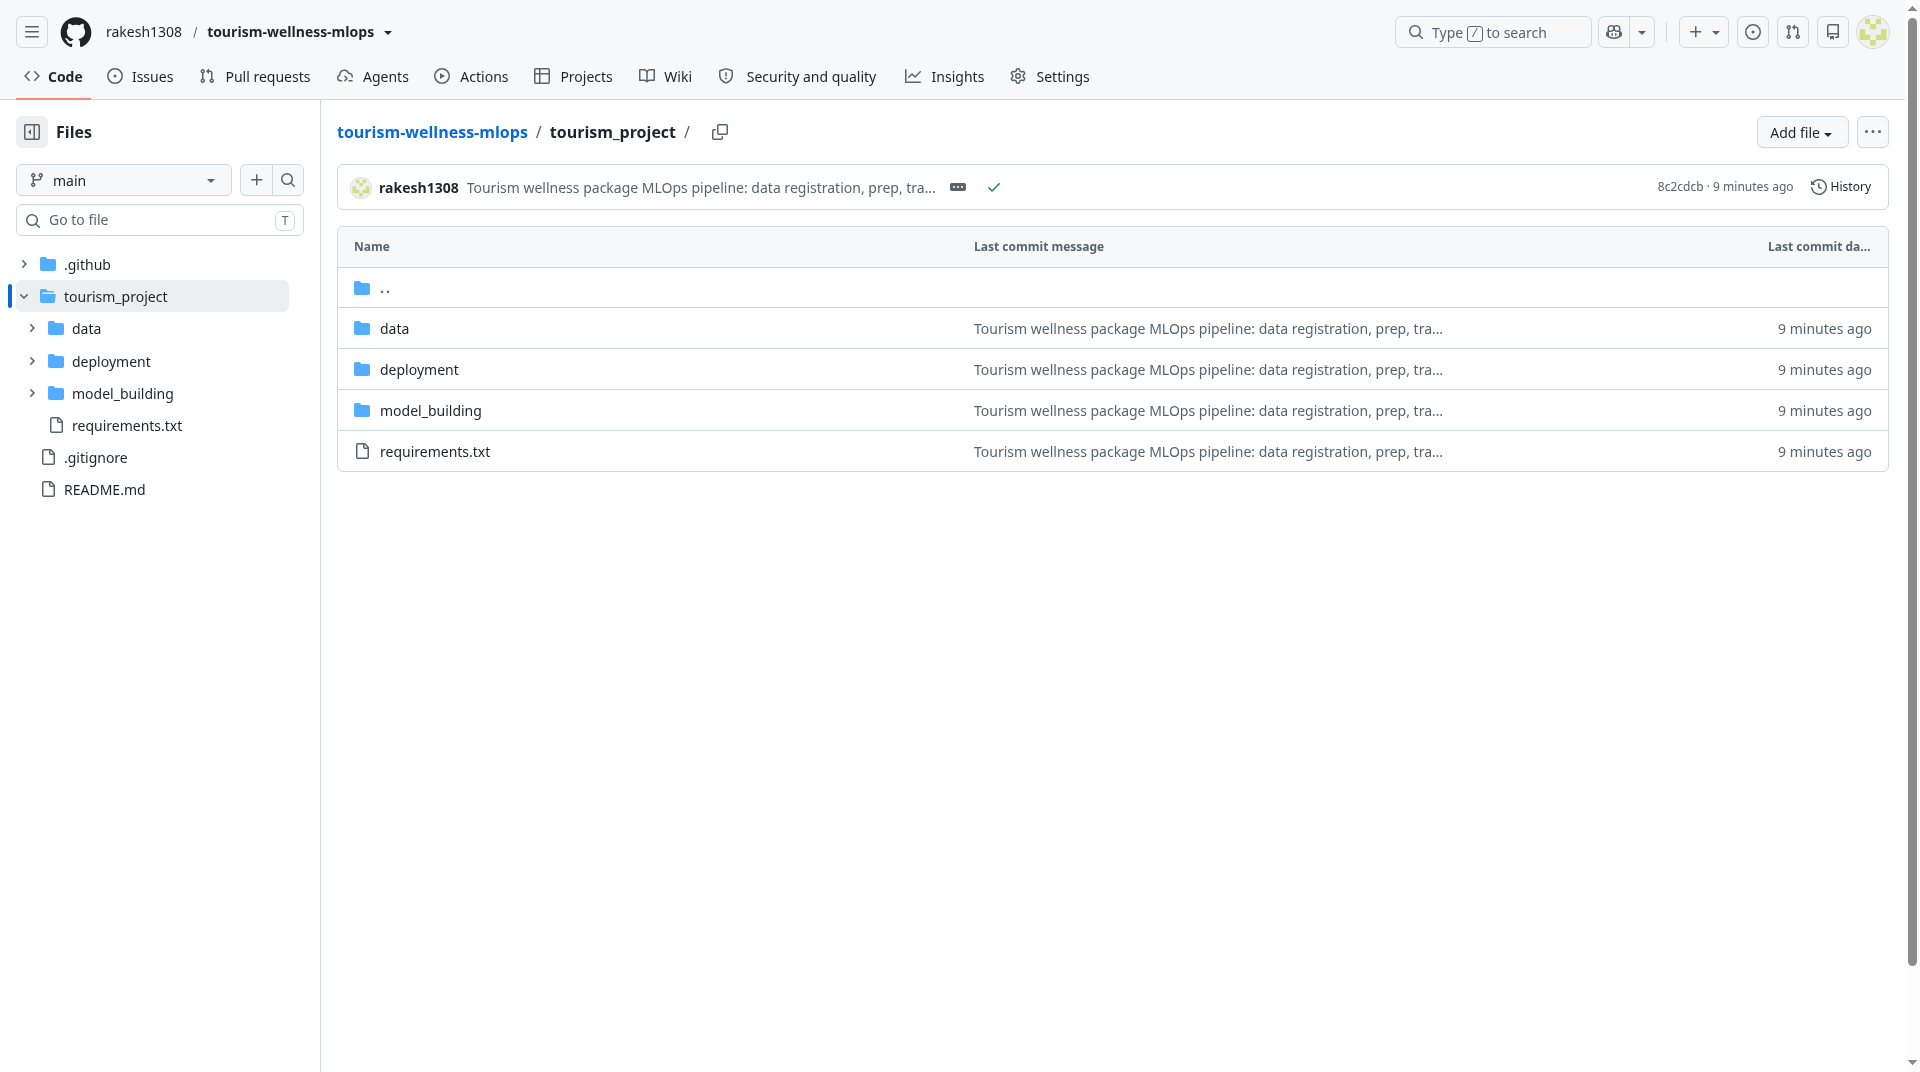

*`tourism_project/` has `data/` (tourism.csv), `model_building/` (data_register.py, prep.py, train.py) and `deployment/` (app.py, requirements.txt and the committed model), matching the structure below.*

**Executed workflow**

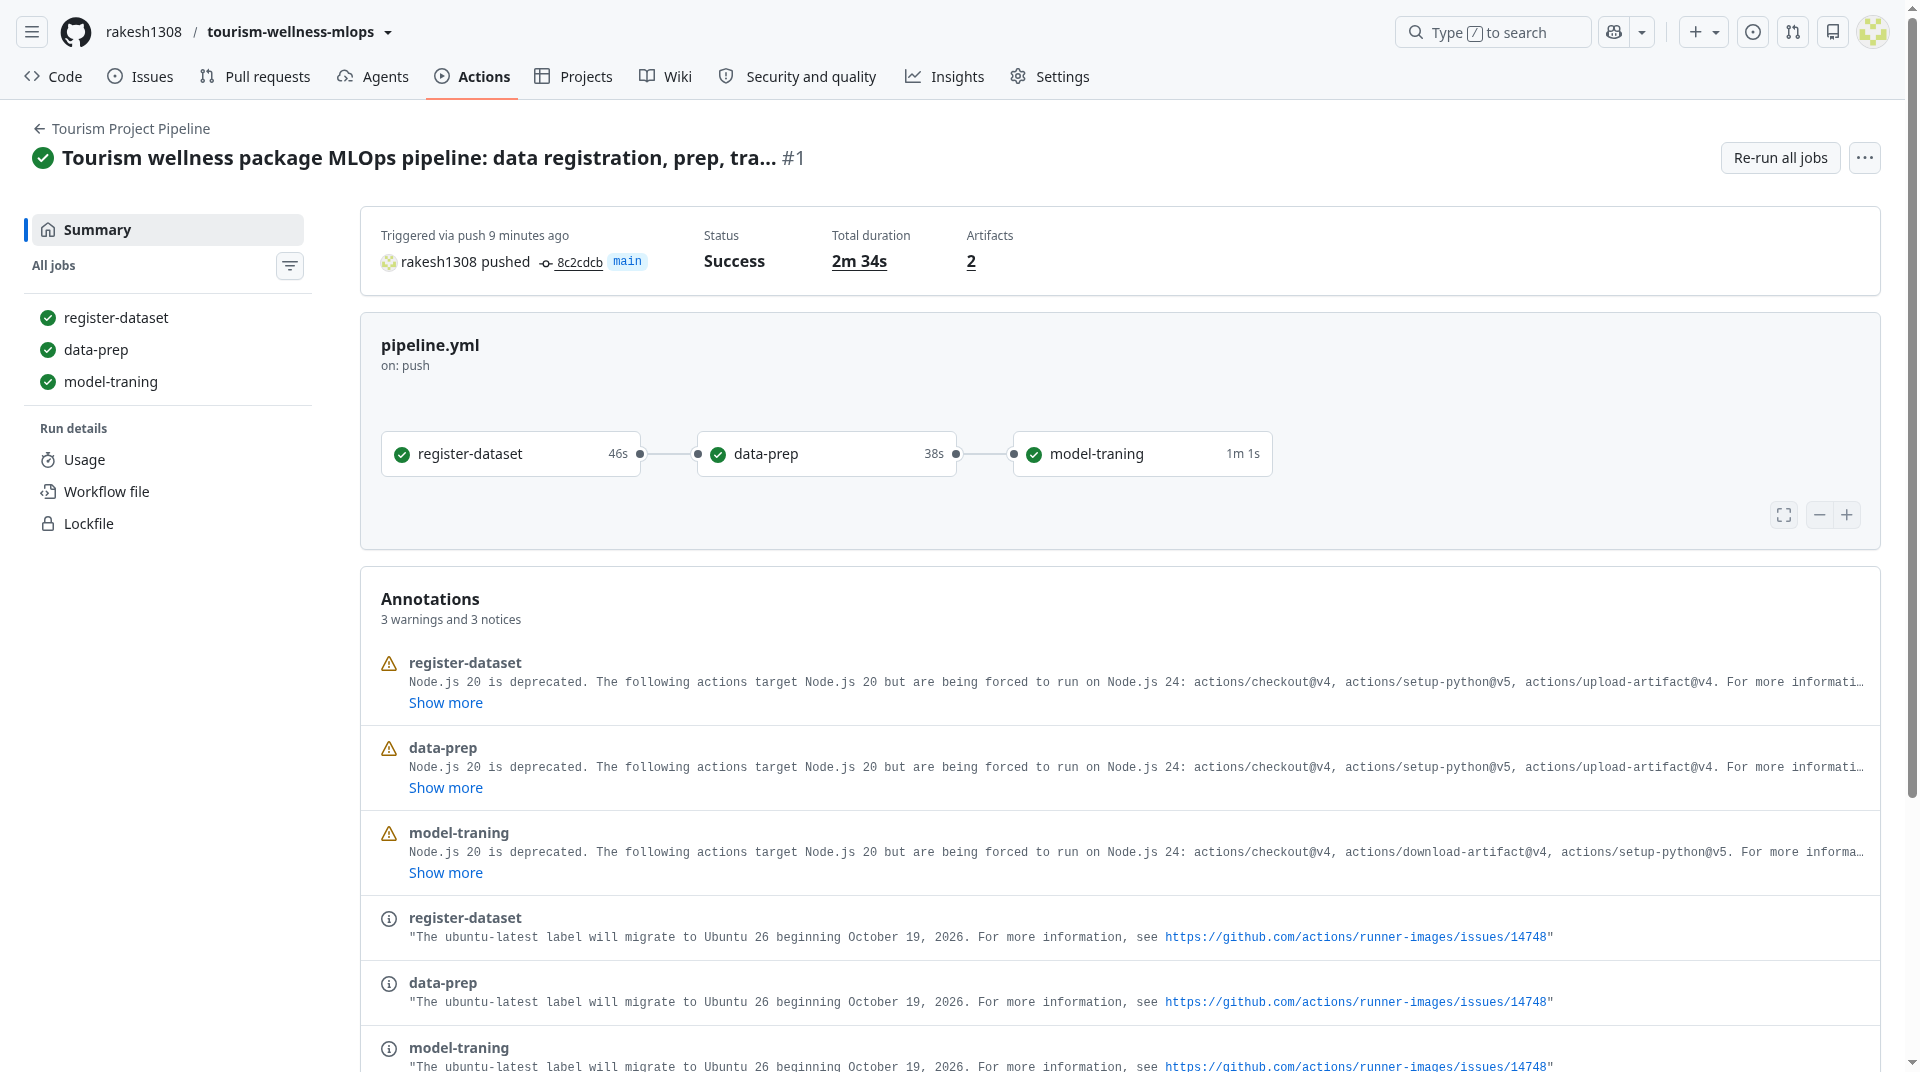

*Run #1 of **Tourism Project Pipeline** was triggered by my push to `main`. All 3 jobs are green: `register-dataset` (46s) → `data-prep` (38s) → `model-traning` (1m 1s). Total duration was 2m 34s, with 2 artifacts (`registered-data` and `data-splits`). The model trained in CI was identical to the one already in the repo, so the commit step reported "No changes to commit" and the run still finished successfully. This shows the training is reproducible. The annotations are only GitHub notices about Node.js 20 deprecation and the ubuntu-latest runner image, not errors.*

In [36]:
# Folder structure of the repository I pushed
# (local-only artefacts such as mlruns/ and the split CSVs are git-ignored, so they are excluded here)
def tree(path, indent=""):
    for name in sorted(os.listdir(path)):
        full = os.path.join(path, name)
        if os.path.isdir(full):
            print(f"{indent}{name}/"); tree(full, indent + "    ")
        else:
            print(f"{indent}{name}")
print("tourism-wellness-mlops/")
print("    .gitignore"); print("    .github/"); tree(".github", "        ")
print("    tourism_project/"); tree("tourism_project", "        ")

tourism-wellness-mlops/
    .gitignore
    .github/
        workflows/
            pipeline.yml
    tourism_project/
        data/
            tourism.csv
        deployment/
            app.py
            best_tourism_model_v1.joblib
            model_metrics.json
            requirements.txt
        model_building/
            data_register.py
            prep.py
            train.py
        requirements.txt


## Streamlit Community Cloud
- **Live app:** https://wellness-tourism-mlops-rakesh.streamlit.app/

**Note on Hugging Face Spaces:** the submission guidelines mention Hugging Face Spaces, but the rubric and the course template specify Streamlit Community Cloud. So my frontend is deployed on **Streamlit Community Cloud**, and the public app is at the link above.

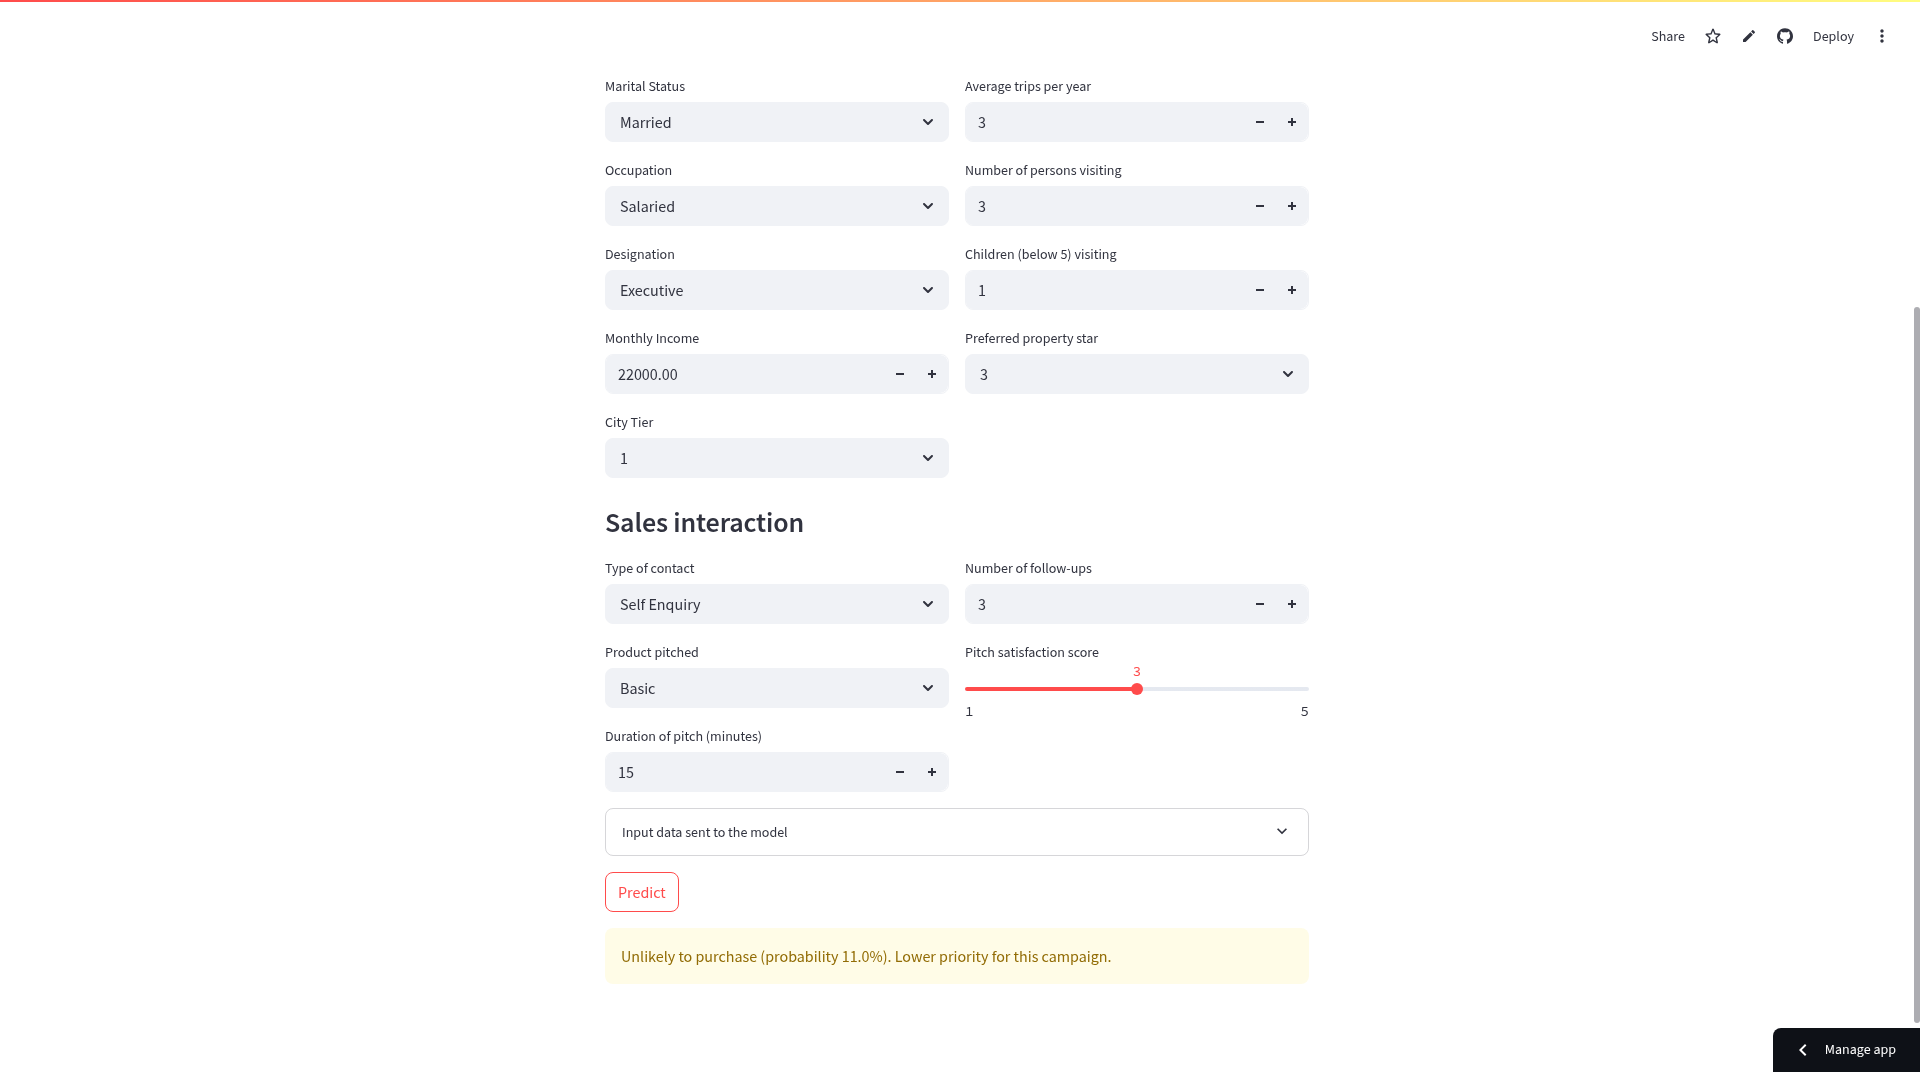

*Test prediction: I set Age to 42 and kept the other defaults (Married, Salaried Executive, income 22,000, City Tier 1, Self Enquiry, Basic package, 3 follow-ups). The app returned **"Unlikely to purchase (probability 11.0%)"**. That matches the EDA, since married customers in Tier 1 cities convert at well below the ~19% base rate.*

# Actionable Insights and Recommendations

**What the model and the data told me**
1. **Passport holders are the best prospects.** They convert at ~36% against ~12% for those without, and passport is the model's top feature. Every campaign list should be sorted with passport holders first.
2. **The entry-level segment buys most.** Executives pitched the Basic package convert at ~30%, while AVP/VP pitched Super Deluxe/King convert under 9%. The wellness package should have an affordable entry tier for this group. For senior customers, the pitch needs a different value story (premium wellness, exclusivity) rather than more of the same.
3. **Single and unmarried customers convert 2-3x better than married ones.** Wellness, solo-retreat and "recharge" messaging should target them. For married customers, a couples/family wellness bundle is worth testing.
4. **Follow-ups work.** Conversion climbs from ~13% (1 follow-up) to ~40% (6 follow-ups). The sales team should keep following up with customers the model scores high, rather than dropping them after one or two calls.
5. **Tier 2 and Tier 3 cities convert better (~25%) than Tier 1 (~17%),** even though most leads come from Tier 1. These cities are under-served and deserve more marketing spend.
6. **Large Business owners** (29%) are a small but valuable segment to target with premium wellness offers.

**How the business should use the model**
- Score every new lead before the first call and contact leads with probability ≥ 0.45 first. On the test set this catches **82% of buyers**, and **86% of the customers it flags actually buy**, against a base rate of ~19% if leads were called at random.
- Because the pipeline runs on every push to `main`, new customer data added to `tourism_project/data/` automatically retrains, re-evaluates and re-deploys the model. The model stays current as customer behaviour changes.
- Next improvements: monitor monthly precision/recall on fresh campaign results, add a drift check to the registration job, and extend the grid with regularisation (e.g. `min_child_weight`, shallower trees) to reduce the train/test gap.

<font size=6 color="navyblue">Power Ahead!</font>
___